# Experiment 2: longer training in the dependent-block setting

This notebook follows up the `dependent_blocks` setting (Case 3) of [von Kügelgen et al. (2021)](https://arxiv.org/abs/2106.04619). It compares invariant and perturbed original content while holding the world parameters and mixing network fixed at world seed 0.

The saved study uses five encoder outputs, training seeds 0, 1 and 2, content perturbation strengths $\sigma_c\in\{0,0.1\}$, and 1,024 positive pairs plus 1,024 independent negatives per update. Six training trajectories each supply checkpoints at 10,000, 30,000 and 60,000 updates. The two conditions share initialization and sampling streams within each training seed. Variation across seeds therefore measures training variability within one fixed world, rather than variation across covariance and mixing draws.

The completed recovery tables, per-seed diagnostics and report Figure 2 are embedded. The default Run All executes the focused study near the end. The earlier four-setting table and independent strength sweep are retained but disabled through `RUN_MAIN_TABLE=False` and `RUN_ORIGINAL_STRENGTH_SWEEP=False`.

Models, optimizer states, random-generator states and evaluation arrays are written to `extension_dependent_blocks_followup`. Compatible checkpoints support resuming training and reusing completed evaluations. These external files are not bundled with the saved notebook; fresh execution without them trains the trajectories. Use persistent storage when running in Colab.


## Part A: shared simulation setup

These cells define the Gaussian reference model, latent augmentation, fixed mixing network, encoder, and contrastive loss. The implementation is adapted from the synthetic experiments in [von Kügelgen et al. (2021)](https://arxiv.org/abs/2106.04619) and their [released code](https://github.com/ysharma1126/ssl_identifiability/tree/ee46a35acf68461172b3eaeeb1d6fbc779fce661). Part B specifies the distributions, augmentation rules, output dimensions, and training budgets used in this notebook.

The notebook is self-contained. Run the setup before executing Part B; the saved tables and figures can be read without rerunning training.


### Environment and settings

The code uses Python, PyTorch, NumPy, SciPy, pandas, Matplotlib, and scikit-learn. The next cell records the software versions used for the saved execution. Dependencies are listed in the repository's `requirements.txt`. The device setting selects CUDA, then Apple MPS, then CPU when available; rerun results can vary across devices and software versions.


In [1]:
import copy
import math
import platform
import time
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import wishart
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

import torch
from torch import nn
from IPython.display import display

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelsize": 11, "axes.titlesize": 12, "font.size": 10,
})

versions = {
    "Python": platform.python_version(), "PyTorch": torch.__version__,
    "NumPy": np.__version__, "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}
display(pd.Series(versions, name="Version").to_frame())

,Version
Python,3.13.16
PyTorch,2.11.0+cu130
NumPy,2.1.3
SciPy,1.16.3
scikit-learn,1.6.1


### Reference scenarios

The four scenarios follow the synthetic comparisons in Section 5.1 of [von Kügelgen et al. (2021)](https://arxiv.org/abs/2106.04619).

| Scenario | Style-coordinate selection probability | Dependence within blocks | Style depends on content |
| --- | ---: | --- | --- |
| `independent_all` | 1.00 | No | No |
| `independent_partial` | 0.75 | No | No |
| `dependent_blocks` | 0.75 | Yes | No |
| `content_causes_style` | 0.75 | Yes | Yes |

The reference model has five content factors and five style factors. `representation_dim` sets the number of encoder outputs, independently of those latent dimensions. Each update uses fresh simulated data; `batch_size` sets both the number of positive pairs and the size of the independent negative pool. The experiment cells below override the reference settings as needed.


In [2]:
SCENARIO = "independent_partial"

SCENARIOS = {
    "independent_all":      (1.00, False, False),
    "independent_partial":  (0.75, False, False),
    "dependent_blocks":     (0.75, True,  False),
    "content_causes_style": (0.75, True,  True),
}

@dataclass
class Settings:
    seed: int = 7                          # Controls randomness so a run can be repeated.
    content_dim: int = 5                   # Number of true content variables, unchanged across paired views.
    style_dim: int = 5                     # Number of true style variables, which may change across views.
    representation_dim: int = 5            # Number of encoder outputs; equals content_dim.
    style_change_prob: float = 0.75        # Probability that each style coordinate is selected for change ("Biased Coin")
    statistical_dependence: bool = False   # If True, allow correlations within content, style noise, and augmentation noise.
    content_dependent_style: bool = False  # If True, generate style as s = a + Bc + noise.
    marginal_std: float = 1.0              # Standard deviation of content and residual style noise when dependence is off.
    style_noise_std: float = 1.0           # Standard deviation of noise added to selected style coordinates when dependence is off.
    mixing_layers: int = 3                 # Number of linear layers in the fixed latent-to-observation network.
    condition_pool: int = 25000            # Number of random matrices used to estimate a conditioning threshold.
    condition_quantile: float = 0.001      # Set the threshold using roughly the best-conditioned 0.1% of those matrices.
    learning_rate: float = 1e-4            # Controls the size of the encoder's parameter updates during training.
    temperature: float = 1.0               # Scales distances in the contrastive loss; smaller values sharpen comparisons.
    batch_size: int = 1024                  # Positive pairs per update; also the number of independent negative examples.
    steps: int = 10000                      # Total number of encoder parameter updates.
    log_every: int = 200                   # Print training progress every this many updates.
    probe_train_size: int = 3000            # Examples used to fit evaluation models that predict latents from representations.
    probe_test_size: int = 5000            # Separate examples used to test those evaluation models.
    device: str = "auto"                   # Automatically choose CUDA, then MPS, then CPU; can also set one explicitly.

cfg = Settings()
(cfg.style_change_prob, cfg.statistical_dependence,
 cfg.content_dependent_style) = SCENARIOS[SCENARIO]

# Original script's training scale (not enabled for this demonstration):
# cfg.batch_size = 6144
# cfg.steps = 100001
# The original nonlinear evaluation fits probes on 5 * 4096 examples and
# evaluates on 10 fresh batches of 4096. Kernel regression at that size is costly.

assert min(cfg.content_dim, cfg.style_dim, cfg.representation_dim) >= 1
assert 0 <= cfg.style_change_prob <= 1
assert min(cfg.marginal_std, cfg.style_noise_std, cfg.temperature) > 0
assert cfg.steps > 0 and cfg.batch_size > 1

if cfg.device != "auto":
    device = torch.device(cfg.device)
elif torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

torch.manual_seed(cfg.seed)
torch.set_num_threads(2)  # Avoid oversubscribing CPU cores in small examples.
latent_dim = cfg.content_dim + cfg.style_dim
print(f"Scenario: {SCENARIO}; device: {device}")
display(pd.Series(asdict(cfg), name="Setting").to_frame())

Scenario: independent_partial; device: cuda


,Setting
seed,7
content_dim,5
style_dim,5
representation_dim,5
style_change_prob,0.75
statistical_dependence,False
content_dependent_style,False
marginal_std,1.0
style_noise_std,1.0
mixing_layers,3


### Gaussian reference model

The reference sampler draws

$$
c\sim N(0,\Sigma_c),\qquad
s=a+Bc+\varepsilon_s,\qquad
\varepsilon_s\sim N(0,\Sigma_s),
$$

with independent draws of $c$ and $\varepsilon_s$. In the independent scenarios, the covariance matrices are scalar multiples of the identity. In the dependent scenarios, Wishart draws provide positive definite covariance matrices and replace the scalar variance settings. Setting `content_dependent_style=True` introduces the term $a+Bc$; otherwise $a=B=0$.

The world parameters are fixed within a run. Repeated samples therefore come from the same data-generating distribution. Experiment-specific samplers are defined in Part B.


In [3]:
def make_world(settings):
    """Create fixed parameters of the data distribution on the CPU."""
    rng = np.random.default_rng(settings.seed)
    nc, ns = settings.content_dim, settings.style_dim

    def covariance(dim, std):
        if settings.statistical_dependence:
            # Match the intended Wishart construction in the original experiment.
            matrix = np.atleast_2d(wishart.rvs(df=dim, scale=np.eye(dim), random_state=rng))
        else:
            matrix = (std ** 2) * np.eye(dim)
        return torch.tensor(matrix, dtype=torch.float64)

    Sigma_c = covariance(nc, settings.marginal_std)
    Sigma_s = covariance(ns, settings.marginal_std)
    Sigma_aug = covariance(ns, settings.style_noise_std)
    # As in upstream spaces.py, explicit covariances supersede the std arguments.
    a = torch.zeros(ns)
    B = torch.zeros(ns, nc)
    if settings.content_dependent_style:
        a = torch.tensor(rng.standard_normal(ns), dtype=torch.float32)
        B = torch.tensor(rng.standard_normal((ns, nc)), dtype=torch.float32)
    return {
        "L_c": torch.linalg.cholesky(Sigma_c).float(),
        "L_s": torch.linalg.cholesky(Sigma_s).float(),
        "L_aug": torch.linalg.cholesky(Sigma_aug).float(),
        "a": a, "B": B,
    }

world = make_world(cfg)

def sample_latents(size, generator):
    """Draw z=(c,s). Latent values are used by the simulator and evaluator."""
    c = torch.randn(size, cfg.content_dim, generator=generator) @ world["L_c"].T
    eps_s = torch.randn(size, cfg.style_dim, generator=generator) @ world["L_s"].T
    s = world["a"] + c @ world["B"].T + eps_s
    return torch.cat([c, s], dim=1)

display(pd.DataFrame({
    "block": ["content", "style residual", "augmentation noise"],
    "dimension": [cfg.content_dim, cfg.style_dim, cfg.style_dim],
    "covariance": ["L_c @ L_c.T", "L_s @ L_s.T", "L_aug @ L_aug.T"],
}))

,block,dimension,covariance
0,content,5,L_c @ L_c.T
1,style residual,5,L_s @ L_s.T
2,augmentation noise,5,L_aug @ L_aug.T


### Reference augmentation and negative samples

The reference augmentation copies content and adds masked Gaussian noise to style:

$$
M_j\sim\operatorname{Bernoulli}(p),\qquad
\tilde s=s+M\odot\eta,\qquad
\eta\sim N(0,\Sigma_{\mathrm{aug}}).
$$

The mask entries are independent, and the mask and noise are independent of the original latents. The operator $\odot$ denotes coordinatewise multiplication. When $p>0$ and $\Sigma_{\mathrm{aug}}$ is positive definite, every style coordinate can vary locally. The negative samples are independent draws from the original latent distribution. Part B defines any changes to this reference augmentation.


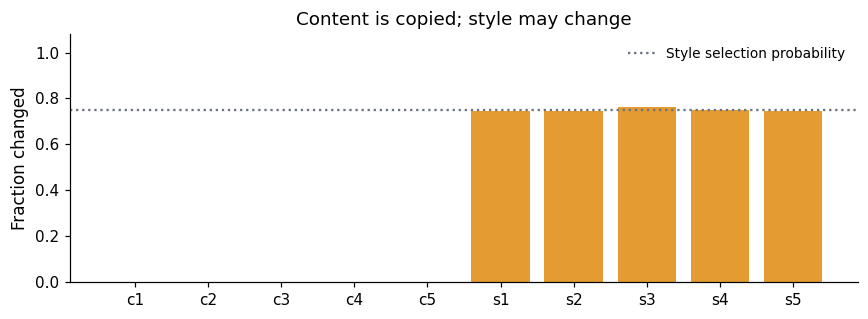

In [4]:
def augment_latents(z, generator):
    nc = cfg.content_dim
    style = z[:, nc:]
    mask = (torch.rand(style.shape, generator=generator) < cfg.style_change_prob)
    noise = torch.randn(style.shape, generator=generator) @ world["L_aug"].T
    changed_style = style + mask * noise
    return torch.cat([z[:, :nc], changed_style], dim=1)

def sample_triplet(size, generator):
    z = sample_latents(size, generator)
    z_negative = sample_latents(size, generator)
    z_augmented = augment_latents(z, generator)
    return z, z_augmented, z_negative

# A separate random stream keeps this inspection from changing training data.
inspection_rng = torch.Generator().manual_seed(cfg.seed + 10)
z_check, z_aug_check, _ = sample_triplet(5000, inspection_rng)
assert torch.equal(z_check[:, :cfg.content_dim], z_aug_check[:, :cfg.content_dim])
change_rates = (z_check != z_aug_check).float().mean(dim=0).numpy()
names = ([f"c{i+1}" for i in range(cfg.content_dim)] +
         [f"s{i+1}" for i in range(cfg.style_dim)])

fig, ax = plt.subplots(figsize=(8, 3))
colors = ["#227c9d"] * cfg.content_dim + ["#e49b32"] * cfg.style_dim
ax.bar(names, change_rates, color=colors)
ax.axhline(cfg.style_change_prob, color="#6b7280", linestyle=":", label="Style selection probability")
ax.set(ylim=(0, 1.08), ylabel="Fraction changed", title="Content is copied; style may change")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### Fixed mixing network

The mixing network maps $z=(c,s)$ to $x=f(z)$. Its square nonsingular weight matrices and LeakyReLU activations with nonzero negative slope make the map invertible. The code selects well-conditioned matrices to limit numerical distortion, then freezes the mixing network during encoder training.

LeakyReLU has a kink at zero, so this implementation is not smooth everywhere as required by the paper's theoretical model.


In [5]:
def make_mixing(settings):
    """Adapt the upstream well-conditioned, square mixing MLP."""
    n = settings.content_dim + settings.style_dim
    rng = np.random.default_rng(settings.seed + 100)

    def candidate():
        matrix = rng.uniform(-1, 1, size=(n, n))
        return matrix / np.linalg.norm(matrix, axis=0, keepdims=True)

    conditions = np.array([
        np.linalg.cond(candidate()) for _ in range(settings.condition_pool)
    ])
    threshold = np.sort(conditions)[int(settings.condition_pool * settings.condition_quantile)]
    modules, accepted_conditions = [], []
    for layer in range(settings.mixing_layers):
        matrix = candidate()
        while np.linalg.cond(matrix) > threshold:
            matrix = candidate()
        linear = nn.Linear(n, n, bias=False)
        with torch.no_grad():
            linear.weight.copy_(torch.tensor(matrix, dtype=torch.float32))
        modules.append(linear)
        accepted_conditions.append(np.linalg.cond(matrix))
        if layer < settings.mixing_layers - 1:
            modules.append(nn.LeakyReLU(negative_slope=0.2))
    network = nn.Sequential(*modules).to(device)
    network.requires_grad_(False)
    network.eval()
    return network, accepted_conditions

mixing, condition_numbers = make_mixing(cfg)
print("Mixing layer condition numbers:", np.round(condition_numbers, 2))
print("Mixing parameters trainable:", any(p.requires_grad for p in mixing.parameters()))

with torch.no_grad():
    x_check = mixing(z_check[:5].to(device))
print("Latent shape:", tuple(z_check[:5].shape))
print("Observation shape:", tuple(x_check.shape))

Mixing layer condition numbers: [4.56 4.26 4.91]
Mixing parameters trainable: False
Latent shape: (5, 10)
Observation shape: (5, 10)


### Encoder

The base encoder uses the hidden-layer widths and LeakyReLU activations of the released `main_mlp.py`, with an unbounded final linear layer. Its output dimension is $d=\texttt{representation_dim}$. The learned composite map is $h=g\circ f$, from the ten latent coordinates to $d$ representation coordinates. Part B specifies the output dimension and any additional output transformation.


In [6]:
def make_encoder(settings):
    n = settings.content_dim + settings.style_dim
    # Same hidden widths as main_mlp.py; final layer has no activation.
    widths = [n, n * 10, n * 50, n * 50, n * 50, n * 50, n * 10,
              settings.representation_dim]
    modules = []
    for i, (n_in, n_out) in enumerate(zip(widths[:-1], widths[1:])):
        modules.append(nn.Linear(n_in, n_out))
        if i < len(widths) - 2:
            modules.append(nn.LeakyReLU(negative_slope=0.01))
    return nn.Sequential(*modules).to(device)

torch.manual_seed(cfg.seed + 200)
encoder = make_encoder(cfg)
initial_encoder = copy.deepcopy(encoder).eval()
print(encoder)
print("Trainable encoder parameters:", sum(p.numel() for p in encoder.parameters()))

Sequential(
  (0): Linear(in_features=10, out_features=100, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=100, out_features=500, bias=True)
  (3): LeakyReLU(negative_slope=0.01)
  (4): Linear(in_features=500, out_features=500, bias=True)
  (5): LeakyReLU(negative_slope=0.01)
  (6): Linear(in_features=500, out_features=500, bias=True)
  (7): LeakyReLU(negative_slope=0.01)
  (8): Linear(in_features=500, out_features=500, bias=True)
  (9): LeakyReLU(negative_slope=0.01)
  (10): Linear(in_features=500, out_features=100, bias=True)
  (11): LeakyReLU(negative_slope=0.01)
  (12): Linear(in_features=100, out_features=5, bias=True)
)
Trainable encoder parameters: 853705


### Contrastive objective

Let $u_i=g(x_i)$, $v_i=g(\tilde x_i)$, and $w_j=g(x_j^-)$. The first two form a positive pair; $w_j$ comes from the independent negative pool. Define

$$
d_i^+=\|u_i-v_i\|_2^2,\qquad d_{ij}^-=\|u_i-w_j\|_2^2.
$$

For batch size $m$ and temperature $\tau$, the implemented loss is

$$
\frac1m\sum_{i=1}^m\left[
\frac{d_i^+}{\tau}
+\log\left(\frac{e^{-d_i^+/\tau}+\sum_{j=1}^m e^{-d_{ij}^-/\tau}}{m+1}\right)
\right].
$$

This matches the released implementation's squared-distance objective at $p=2$ and $\alpha=0.5$. Dividing by $m+1$ inside the logarithm shifts the usual summed-denominator loss by a constant; negative loss values are therefore expected. The loss encourages agreement within positive pairs relative to independent negatives.

This finite-batch contrastive objective does not compute differential entropy directly. It differs from the population alignment–entropy objective on a bounded output domain in Theorem 4.4; the experiments assess finite-training behavior.


In [7]:
def contrastive_loss(anchor, positive, negative, temperature=1.0):
    """Same objective as LpSimCLRLoss at its default p=2, alpha=0.5."""
    positive_distance = (anchor - positive).square().sum(dim=1)
    # Algebraically equal to all pairwise squared differences, using less memory.
    negative_distance = (
        anchor.square().sum(dim=1, keepdim=True)
        + negative.square().sum(dim=1).unsqueeze(0)
        - 2 * anchor @ negative.T
    ).clamp_min(0)
    all_distances = torch.cat([negative_distance, positive_distance[:, None]], dim=1)
    alignment = positive_distance / temperature
    contrast = torch.logsumexp(-all_distances / temperature, dim=1)
    contrast = contrast - math.log(all_distances.shape[1])
    loss = (alignment + contrast).mean()
    return loss, alignment.mean().detach(), contrast.mean().detach()

zero = torch.zeros(8, cfg.representation_dim, device=device)
collapsed_loss, _, _ = contrastive_loss(zero, zero, zero, cfg.temperature)
print(f"Loss of a constant representation: {collapsed_loss.item():.3f}")

Loss of a constant representation: 0.000


## Part B: Experiment 2


## Paired invariant and perturbed original content

The experiment compares $\sigma_c=0$ and $\sigma_c=0.1$. In the perturbed condition, each original-content coordinate receives independent centered Gaussian noise with standard deviation $0.1$ times its population standard deviation. Thus

$$
\pi(c_j)=\frac{\operatorname{Var}(\widetilde c_j-c_j)}{\operatorname{Var}(c_j)}=0.01.
$$

Within each paired comparison, the world, mixing network, encoder initialization, training random draws and probe observations are matched. The sampler draws content masks and noise even when $\sigma_c=0$, keeping subsequent random draws aligned. Style is perturbed from its original sampled value; it is not regenerated from perturbed content.

The coordinate price $0.01$ does not imply that every linear content direction has the same price when coordinates are correlated. The covariance diagnostics below describe this distinction. They provide a linear benchmark, not a guarantee for the trained nonlinear encoders.


In [8]:
# CHANGED [1, 5]: paired controls and versioned, configuration-aware cache.
import hashlib
import json
from dataclasses import asdict, replace
from scipy.linalg import eigh

# CHANGED [7]: default Run All now launches only the focused study added below.
RUN_MAIN_TABLE = False                 # True restores the original four-setting comparison
RUN_ORIGINAL_STRENGTH_SWEEP = False    # True restores the original independent sweep

CONTENT_SIGMA = 0.10
CONTENT_CHANGE_PROB = 1.0
SEEDS = [0, 1, 2]
STEPS = cfg.steps
COMPETITION_SIGMAS = [0.0, 0.1, 0.3, 0.6, 1.0]  # independent_all, seed 0 only; [] skips
PRICE_SAMPLES = 50000
EXPERIMENT_VERSION = 'exp2_paired_v2'  # bump this after changing the sampling/training code
EXT2_DIR = Path('extension_perturbed_content_v2')
EXT2_DIR.mkdir(parents=True, exist_ok=True)

ROWS = [
    ('independent_all',      1.00, False, False),
    ('independent_partial',  0.75, False, False),
    ('dependent_blocks',     0.75, True,  False),
    ('content_causes_style', 0.75, True,  True),
]
PAPER = {
    'independent_all':      (1.00, 0.00, 0.07, 0.00),
    'independent_partial':  (1.00, 0.00, 0.06, 0.05),
    'dependent_blocks':     (0.98, 0.03, 0.37, 0.05),
    'content_causes_style': (0.99, 0.01, 0.80, 0.08),
}
NC, NS = cfg.content_dim, cfg.style_dim
N = NC + NS
COORDS = [f'c{i+1}' for i in range(NC)] + [f's{i+1}' for i in range(NS)]
MAIN_SIGMAS = [0.0, CONTENT_SIGMA]
KRR_GRID = {'kernelridge__alpha': [1.0, 0.1, 0.01, 0.001],
            'kernelridge__gamma': [float(g) for g in np.logspace(-2, 2, 4)]}

assert CONTENT_SIGMA > 0 and 0 < CONTENT_CHANGE_PROB <= 1
assert len(SEEDS) == len(set(SEEDS)) and len(SEEDS) > 0
assert STEPS > 0 and PRICE_SAMPLES > 1
assert all(s >= 0 for s in COMPETITION_SIGMAS)
print(f'Original paired table enabled: {RUN_MAIN_TABLE}; device: {device}.')
print('Original independent sweep enabled:', RUN_ORIGINAL_STRENGTH_SWEEP)


def draw_z(settings, w, size, gen):
    c = torch.randn(size, settings.content_dim, generator=gen) @ w["L_c"].T
    eps = torch.randn(size, settings.style_dim, generator=gen) @ w["L_s"].T
    return torch.cat([c, w["a"] + c @ w["B"].T + eps], dim=1)


def content_std(w):
    """Marginal std of each content coordinate: sqrt(diag(L_c L_c^T))."""
    return torch.sqrt((w["L_c"] ** 2).sum(dim=1))


def draw_leaky_triplet(settings, w, size, gen, sigma_c, p_c):
    """(z, z~, z_negative) where style is nudged as in the paper AND content is nudged too.

    Content nudge: with probability p_c per coordinate, add N(0, (sigma_c * std_l)^2),
    i.e. a nudge of sigma_c times the coordinate's natural spread. Each coordinate price is then
    pi_c = p_c * sigma_c^2 in every scenario. Direction prices can differ under correlation.
    """
    z = draw_z(settings, w, size, gen)
    # VERIFIED: the released main_mlp.py also draws negatives from the original marginal.
    z_neg = draw_z(settings, w, size, gen)
    c, s = z[:, :settings.content_dim], z[:, settings.content_dim:]
    mask_s = torch.rand(s.shape, generator=gen) < settings.style_change_prob
    noise_s = torch.randn(s.shape, generator=gen) @ w["L_aug"].T
    # CHANGED [1]: keep these draws unconditional, including when sigma_c == 0.
    # This matches the random training draws across invariant/perturbed controls.
    mask_c = torch.rand(c.shape, generator=gen) < p_c
    noise_c = torch.randn(c.shape, generator=gen) * (sigma_c * content_std(w))
    z_aug = torch.cat([c + mask_c * noise_c, s + mask_s * noise_s], dim=1)
    return z, z_aug, z_neg


def empirical_prices(settings, w, sigma_c, p_c, n=50000):
    """r_l = Var(z_l~ - z_l) / Var(z_l) estimated from n pairs, for every coordinate."""
    z, z_aug, _ = draw_leaky_triplet(settings, w, n, torch.Generator().manual_seed(12345), sigma_c, p_c)
    return ((z_aug - z).var(dim=0) / z.var(dim=0)).numpy()

Original paired table enabled: False; device: cuda.
Original independent sweep enabled: False


### Coordinate and direction prices

The tables report exact coordinate prices for every setting and seed. For $q=\alpha^\top z$, the linear-direction price is

$$
\pi(q)=\frac{\alpha^\top D\alpha}{\alpha^\top\Sigma_z\alpha},
\qquad D=\operatorname{Cov}(\widetilde z-z),\quad \Sigma_z=\operatorname{Cov}(z).
$$

The generalized eigenproblem $D\alpha=\lambda\Sigma_z\alpha$ gives reference directions ordered by price. Content-dependent style requires the full joint covariance, since these directions may combine content and style. Coordinate prices alone do not determine the cheapest subspace. In particular, for `content_causes_style`, seed 2 gives $\pi(s_1)\approx0.00441$, below the perturbed-content coordinate price $0.01$.

The ideal recovery columns describe the linear benchmark and are omitted at cutoff ties. They are distinct from the fitted probe results.


In [9]:
# ADDED [3, 4]: exact coordinate prices and full covariance-based direction prices.
# These functions use NumPy/SciPy and do not require training a model.
def covariance_diagnostics(Sigma_c, Sigma_residual, Sigma_aug, B,
                           p_style, sigma_c, p_content):
    Sigma_c = np.asarray(Sigma_c, dtype=np.float64)
    Sigma_residual = np.asarray(Sigma_residual, dtype=np.float64)
    Sigma_aug = np.asarray(Sigma_aug, dtype=np.float64)
    B = np.asarray(B, dtype=np.float64)
    nc, ns = len(Sigma_c), len(Sigma_residual)
    Sigma_style = Sigma_residual + B @ Sigma_c @ B.T
    Sigma_z = np.block([[Sigma_c, Sigma_c @ B.T],
                        [B @ Sigma_c, Sigma_style]])
    # The content sampler uses independent coordinatewise changes, even for correlated c.
    D_content = p_content * sigma_c**2 * np.diag(np.diag(Sigma_c))
    # Independent masks give factor p on diagonal entries and p^2 off the diagonal.
    D_style = (p_style**2 * Sigma_aug
               + p_style * (1 - p_style) * np.diag(np.diag(Sigma_aug)))
    D = np.block([[D_content, np.zeros((nc, ns))],
                  [np.zeros((ns, nc)), D_style]])
    coordinate_prices = np.diag(D) / np.diag(Sigma_z)
    return Sigma_z, D, coordinate_prices, D_content, D_style


def linear_price_directions(Sigma_z, D):
    """Columns alpha[:, k] define unit-population-variance quantities z @ alpha[:, k]."""
    Sigma_z = (np.asarray(Sigma_z) + np.asarray(Sigma_z).T) / 2
    D = (np.asarray(D) + np.asarray(D).T) / 2
    prices, alpha = eigh(D, Sigma_z)
    tolerance = 1e-10 * max(1.0, np.max(np.abs(prices)))
    if prices.min() < -tolerance:
        raise ValueError('A materially negative direction price indicates invalid covariances.')
    return np.maximum(prices, 0.0), alpha


def benchmark_coordinate_r2(Sigma_z, alpha, rep_dim):
    """Ideal coordinate recovery from the lowest-price linear subspace, not a fitted probe."""
    cross = Sigma_z @ alpha[:, :rep_dim]
    return np.clip(np.sum(cross**2, axis=1) / np.diag(Sigma_z), 0.0, 1.0)


def world_parameters_numpy(w):
    # Use the actual float32 Cholesky factors used by the sampler, not nominal std settings.
    arrays = {k: v.detach().cpu().numpy().astype(np.float64) for k, v in w.items()}
    return arrays


def world_diagnostics(settings, w, sigma_c, p_c):
    arrays = world_parameters_numpy(w)
    Sc = arrays['L_c'] @ arrays['L_c'].T
    Sr = arrays['L_s'] @ arrays['L_s'].T
    Sa = arrays['L_aug'] @ arrays['L_aug'].T
    Sigma_z, D, prices, Dc, Ds = covariance_diagnostics(
        Sc, Sr, Sa, arrays['B'], settings.style_change_prob, sigma_c, p_c)
    eigenprices, alpha = linear_price_directions(Sigma_z, D)
    content_prices, _ = linear_price_directions(Sc, Dc)
    style_prices, _ = linear_price_directions(Sigma_z[NC:, NC:], Ds)
    d = settings.representation_dim
    gap = float(eigenprices[d] - eigenprices[d-1]) if d < N else None
    strict = d == N or gap > (1e-8 + 1e-6 * max(abs(eigenprices[d-1]), abs(eigenprices[d])))
    # At a cutoff tie, report no unique coordinate prediction: many subspaces can be optimal.
    ideal = benchmark_coordinate_r2(Sigma_z, alpha, d) if strict else None
    return {'Sigma_z': Sigma_z, 'D': D, 'coordinate_prices': prices,
            'direction_prices': eigenprices, 'alpha': alpha,
            'content_direction_prices': content_prices,
            'style_direction_prices': style_prices,
            'cutoff_gap': gap, 'strict_cutoff': bool(strict), 'ideal_coordinate_r2': ideal}


def settings_for(scenario, p_change, statistical, causal, sigma_c, seed):
    return replace(cfg, seed=seed, style_change_prob=p_change,
                   statistical_dependence=statistical, content_dependent_style=causal,
                   representation_dim=NC, steps=STEPS)


# ADDED [3]: display every seed before training, so a seed-zero table cannot hide price reversals.
preflight_rows, direction_reference_rows = [], []
for scenario, p_change, statistical, causal in ROWS:
    for seed in SEEDS:
        for sigma_c in MAIN_SIGMAS:
            settings = settings_for(scenario, p_change, statistical, causal, sigma_c, seed)
            diag = world_diagnostics(settings, make_world(settings), sigma_c, CONTENT_CHANGE_PROB)
            base = {'scenario': scenario, 'seed': seed, 'sigma_c': sigma_c}
            preflight_rows.append({**base, **dict(zip(COORDS, diag['coordinate_prices']))})
            direction_reference_rows.append({
                **base,
                'content_direction_min': float(diag['content_direction_prices'].min()),
                'content_direction_max': float(diag['content_direction_prices'].max()),
                'style_only_direction_min': float(diag['style_direction_prices'].min()),
                'cutoff_price': float(diag['direction_prices'][NC-1]),
                'next_price': float(diag['direction_prices'][NC]),
                'cutoff_gap': diag['cutoff_gap'], 'strict_cutoff': diag['strict_cutoff'],
            })
coordinate_reference = pd.DataFrame(preflight_rows)
direction_reference = pd.DataFrame(direction_reference_rows)
coordinate_reference.to_csv(EXT2_DIR / 'coordinate_prices_exact_all_seeds.csv', index=False)
direction_reference.to_csv(EXT2_DIR / 'direction_price_reference.csv', index=False)
print('Exact coordinate prices, perturbed content: every setting and seed')
display(coordinate_reference[coordinate_reference.sigma_c == CONTENT_SIGMA]
        .set_index(['scenario', 'seed']).drop(columns='sigma_c').round(5))
print('Direction prices at perturbed content; causal predictions use the FULL joint covariance.')
display(direction_reference[direction_reference.sigma_c == CONTENT_SIGMA]
        .set_index(['scenario', 'seed']).drop(columns='sigma_c').round(5))
print('Separate block ranges are descriptive in causal settings: cheapest joint directions may mix c and s.')

Exact coordinate prices, perturbed content: every setting and seed


c1    c2    c3    c4    c5       s1       s2  \
scenario             seed                                                   
independent_all      0     0.01  0.01  0.01  0.01  0.01  1.00000  1.00000   
                     1     0.01  0.01  0.01  0.01  0.01  1.00000  1.00000   
                     2     0.01  0.01  0.01  0.01  0.01  1.00000  1.00000   
independent_partial  0     0.01  0.01  0.01  0.01  0.01  0.75000  0.75000   
                     1     0.01  0.01  0.01  0.01  0.01  0.75000  0.75000   
                     2     0.01  0.01  0.01  0.01  0.01  0.75000  0.75000   
dependent_blocks     0     0.01  0.01  0.01  0.01  0.01  1.80909  0.95142   
                     1     0.01  0.01  0.01  0.01  0.01  0.80141  4.18540   
                     2     0.01  0.01  0.01  0.01  0.01  0.50019  1.35130   
content_causes_style 0     0.01  0.01  0.01  0.01  0.01  0.22532  0.17483   
                     1     0.01  0.01  0.01  0.01  0.01  0.60032  1.04918   
                     2     0.01  0.01  0.01  0.01  0.01  0.00441  0.41397   

                                s3       s4       s5  
scenario             seed                             
independent_all      0     1.00000  1.00000  1.00000  
                     1     1.00000  1.00000  1.00000  
                     2     1.00000  1.00000  1.00000  
independent_partial  0     0.75000  0.75000  0.75000  
                     1     0.75000  0.75000  0.75000  
                     2     0.75000  0.75000  0.75000  
dependent_blocks     0     0.82351  1.27913  2.21549  
                     1     0.95065  0.16036  0.83821  
                     2     0.43673  1.58255  0.31298  
content_causes_style 0     0.31101  0.41557  0.83479  
                     1     0.31293  0.09314  0.46208  
                     2     0.05870  0.54446  0.15704

Direction prices at perturbed content; causal predictions use the FULL joint covariance.


content_direction_min  content_direction_max  \
scenario             seed                                                 
independent_all      0                   0.01000                0.01000   
                     1                   0.01000                0.01000   
                     2                   0.01000                0.01000   
independent_partial  0                   0.01000                0.01000   
                     1                   0.01000                0.01000   
                     2                   0.01000                0.01000   
dependent_blocks     0                   0.00453                0.17124   
                     1                   0.00403                0.30806   
                     2                   0.00477                0.13490   
content_causes_style 0                   0.00453                0.17124   
                     1                   0.00403                0.30806   
                     2                   0.00477                0.13490   

                           style_only_direction_min  cutoff_price  next_price  \
scenario             seed                                                       
independent_all      0                      1.00000       0.01000     1.00000   
                     1                      1.00000       0.01000     1.00000   
                     2                      1.00000       0.01000     1.00000   
independent_partial  0                      0.75000       0.01000     0.75000   
                     1                      0.75000       0.01000     0.75000   
                     2                      0.75000       0.01000     0.75000   
dependent_blocks     0                      0.18937       0.17124     0.18937   
                     1                      0.08351       0.08351     0.30806   
                     2                      0.19674       0.13490     0.19674   
content_causes_style 0                      0.03983       0.14506     0.24933   
                     1                      0.05327       0.08778     0.30249   
                     2                      0.00244       0.10340     0.27425   

                           cutoff_gap  strict_cutoff  
scenario             seed                             
independent_all      0        0.99000           True  
                     1        0.99000           True  
                     2        0.99000           True  
independent_partial  0        0.74000           True  
                     1        0.74000           True  
                     2        0.74000           True  
dependent_blocks     0        0.01813           True  
                     1        0.22455           True  
                     2        0.06184           True  
content_causes_style 0        0.10427           True  
                     1        0.21472           True  
                     2        0.17085           True

Separate block ranges are descriptive in causal settings: cheapest joint directions may mix c and s.


### Training, recovery probes and completed-run caches

Linear regression and RBF kernel ridge regression predict latent coordinates from held-out representations. Kernel hyperparameters are selected on the probe training sample. The direction scores in this section apply the reference linear combinations to the existing coordinate-probe predictions; they do not fit separate kernel probes for each direction.

Completed results are stored in `extension_perturbed_content_v2`. Cache identities include the configuration, world parameters, probe protocol, software versions and device; mismatched files are rejected. These JSON files reuse completed runs, rather than resume interrupted optimizer trajectories. The repository's saved notebook outputs do not include the external cache directory.


In [10]:
def probe_per_coordinate(settings, X_tr, Y_tr, X_te, Y_te):
    """Held-out R² per coordinate with a linear probe and an RBF kernel-ridge probe (per block)."""
    lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, Y_tr)
    lin_pred = lin.predict(X_te)
    lin_r2 = r2_score(Y_te, lin_pred, multioutput="raw_values")
    grid = KRR_GRID  # unchanged hyperparameter grid
    pred = np.zeros_like(Y_te)
    for cols in (slice(0, settings.content_dim), slice(settings.content_dim, None)):
        search = GridSearchCV(make_pipeline(StandardScaler(), KernelRidge(kernel="rbf")),
                              grid, scoring="r2", cv=3, n_jobs=1)
        with threadpool_limits(limits=2):
            search.fit(X_tr, Y_tr[:, cols])
            pred[:, cols] = search.predict(X_te)
    # ADDED [4]: retain existing predictions for derived direction diagnostics.
    return lin_r2, r2_score(Y_te, pred, multioutput="raw_values"), lin_pred, pred





# CHANGED [5]: cache identity includes all settings, actual world parameters and probe protocol.
def cache_configuration(settings, w, scenario, sigma_c, p_c):
    return {'experiment_version': EXPERIMENT_VERSION, 'scenario': scenario,
            'settings': asdict(settings), 'sigma_c': float(sigma_c), 'p_c': float(p_c),
            'price_samples': PRICE_SAMPLES, 'probe_grid': KRR_GRID,
            'runtime_device': str(device), 'software_versions': versions,
            'world_parameters': {k: a.tolist() for k, a in world_parameters_numpy(w).items()}}


def configuration_digest(config):
    payload = json.dumps(config, sort_keys=True, separators=(',', ':'), allow_nan=False)
    return hashlib.sha256(payload.encode()).hexdigest()[:16]


def run_leaky(scenario, p_change, statistical, causal, sigma_c, p_c, seed):
    settings = settings_for(scenario, p_change, statistical, causal, sigma_c, seed)
    w = make_world(settings)
    config = cache_configuration(settings, w, scenario, sigma_c, p_c)
    digest = configuration_digest(config)
    tag = f'{scenario}_sigc{sigma_c:g}_pc{p_c:g}_seed{seed}_steps{settings.steps}_{digest}'
    path = EXT2_DIR / f'{tag}.json'
    if path.exists():
        result = json.loads(path.read_text())
        if result.get('_configuration') != config:
            raise RuntimeError(f'Cache metadata mismatch in {path}; do not reuse this file.')
        print('Verified cache:', tag)
        return result

    diag = world_diagnostics(settings, w, sigma_c, p_c)
    mix, _ = make_mixing(settings)
    torch.manual_seed(settings.seed + 200)
    net = make_encoder(settings)
    opt = torch.optim.Adam(net.parameters(), lr=settings.learning_rate)
    gen = torch.Generator().manual_seed(settings.seed + 300)

    net.train()
    t0 = time.perf_counter()
    for step in range(1, settings.steps + 1):
        z, z_aug, z_neg = draw_leaky_triplet(settings, w, settings.batch_size, gen, sigma_c, p_c)
        with torch.no_grad():
            x, x_aug, x_neg = (mix(v.to(device)) for v in (z, z_aug, z_neg))
        opt.zero_grad(set_to_none=True)
        loss, alignment, _ = contrastive_loss(net(x), net(x_aug), net(x_neg), settings.temperature)
        if not torch.isfinite(loss):
            raise RuntimeError(f'Nonfinite loss in {tag}')
        loss.backward()
        opt.step()
        if step == 1 or step % settings.log_every == 0 or step == settings.steps:
            print(f'{tag}: {step}/{settings.steps} loss {loss.item():.3f} alignment {alignment.item():.3f}')
    net.eval()

    @torch.no_grad()
    def encode(z):
        return torch.cat([net(mix(chunk.to(device))).cpu() for chunk in z.split(512)]).numpy().astype(np.float64)

    # Unchanged: fresh clean observations and identical evaluation draws at each seed.
    z_tr = draw_z(settings, w, settings.probe_train_size, torch.Generator().manual_seed(seed + 400))
    z_te = draw_z(settings, w, settings.probe_test_size, torch.Generator().manual_seed(seed + 500))
    X_tr, X_te = encode(z_tr), encode(z_te)
    Y_tr, Y_te = z_tr.numpy().astype(np.float64), z_te.numpy().astype(np.float64)
    lin, nonlin, lin_pred, kernel_pred = probe_per_coordinate(settings, X_tr, Y_tr, X_te, Y_te)
    sampled_prices = empirical_prices(settings, w, sigma_c, p_c, n=PRICE_SAMPLES)

    # ADDED [4]: direction recovery adds NO neural training or additional kernel fitting.
    # Apply the reference combinations to the existing latent-probe predictions.
    # These derived kernel predictions are not separately tuned direction probes.
    q_test = Y_te @ diag['alpha']
    q_lin = r2_score(q_test, lin_pred @ diag['alpha'], multioutput='raw_values')
    q_kernel = r2_score(q_test, kernel_pred @ diag['alpha'], multioutput='raw_values')

    result = {'scenario': scenario, 'p_change': p_change, 'statistical': statistical, 'causal': causal,
              'sigma_c': sigma_c, 'p_c': p_c, 'seed': seed, 'steps': settings.steps,
              'seconds': time.perf_counter() - t0,
              'content_nonlinear': float(nonlin[:NC].mean()), 'style_nonlinear': float(nonlin[NC:].mean()),
              'content_linear': float(lin[:NC].mean()), 'style_linear': float(lin[NC:].mean()),
              'cutoff_gap': diag['cutoff_gap'], 'strict_cutoff': diag['strict_cutoff'],
              '_configuration': config,
              '_direction_coefficients': diag['alpha'].tolist(),
              '_Sigma_z': diag['Sigma_z'].tolist(), '_D': diag['D'].tolist()}
    result.update({f'r_{n}': float(v) for n, v in zip(COORDS, sampled_prices)})  # compatibility with old files
    result.update({f'price_exact_{n}': float(v) for n, v in zip(COORDS, diag['coordinate_prices'])})
    result.update({f'nonlin_{n}': float(v) for n, v in zip(COORDS, nonlin)})
    result.update({f'lin_{n}': float(v) for n, v in zip(COORDS, lin)})
    result.update({f'price_q{i+1}': float(v) for i, v in enumerate(diag['direction_prices'])})
    result.update({f'linear_q{i+1}': float(v) for i, v in enumerate(q_lin)})
    result.update({f'kernel_derived_q{i+1}': float(v) for i, v in enumerate(q_kernel)})
    for i, name in enumerate(COORDS):
        result[f'benchmark_{name}'] = (float(diag['ideal_coordinate_r2'][i])
                                      if diag['ideal_coordinate_r2'] is not None else None)
    path.write_text(json.dumps(result, indent=2, allow_nan=False))
    return result

### Optional four-setting comparison

This section reproduces the main Experiment 2 comparison when `RUN_MAIN_TABLE=True`; it is disabled in the saved default configuration. It requires three invariant and three perturbed runs for each of four settings, at 10,000 updates. The completed report table is available in [the main Experiment 2 notebook](02_experiment2_perturbed_content.ipynb).

The paired differences use the same seed within each setting. Unlike the focused study below, this comparison varies the world and mixing draw across seeds.


In [11]:
# CHANGED [7]: retain this study, but skip it in the default focused run.
if RUN_MAIN_TABLE:
    # CHANGED [1, 2]: the invariant and perturbed conditions now use the SAME runner for all worlds/seeds.
    paired_records = []
    for scenario, p_change, statistical, causal in ROWS:
        for seed in SEEDS:
            for sigma_c in MAIN_SIGMAS:
                paired_records.append(run_leaky(scenario, p_change, statistical, causal,
                                                 sigma_c, CONTENT_CHANGE_PROB, seed))
    paired = pd.DataFrame(paired_records)
    scalar_cols = [c for c in paired.columns if not c.startswith('_')]
    paired[scalar_cols].to_csv(EXT2_DIR / 'paired_table_runs.csv', index=False)

    def fmt(mean, sd):
        return f'{mean:.2f} ± {sd:.2f}' if np.isfinite(sd) else f'{mean:.2f}'

    def metric_summary(frame, scenario, sigma_c, column):
        values = frame[(frame.scenario == scenario) & (frame.sigma_c == sigma_c)][column]
        return fmt(values.mean(), values.std(ddof=1))

    summary_rows = []
    for scenario, p_change, statistical, causal in ROWS:
        summary_rows.append({
            'scenario': scenario, 'p(chg.)': p_change, 'Stat.': statistical, 'Cau.': causal,
            'content: invariant': metric_summary(paired, scenario, 0.0, 'content_nonlinear'),
            'content: perturbed': metric_summary(paired, scenario, CONTENT_SIGMA, 'content_nonlinear'),
            'style: invariant': metric_summary(paired, scenario, 0.0, 'style_nonlinear'),
            'style: perturbed': metric_summary(paired, scenario, CONTENT_SIGMA, 'style_nonlinear'),
            'content: paper': fmt(PAPER[scenario][0], PAPER[scenario][1]),
            'style: paper': fmt(PAPER[scenario][2], PAPER[scenario][3]),
            'seeds/condition': len(SEEDS),
        })
    matched_table = pd.DataFrame(summary_rows).set_index('scenario')
    matched_table.to_csv(EXT2_DIR / 'table_matched_mean_sd.csv')
    print('Held-out kernel R², mean ± sample standard deviation over seeds. Compare the matched columns.')
    display(matched_table)
    print('Paper values provide context; budget, negatives and probe data differ from its full experiment.')

    # ADDED [2]: paired differences retain the sign and seed variation; no equivalence/significance claim.
    key = ['scenario', 'seed']
    baseline = paired[paired.sigma_c == 0.0].set_index(key)
    perturbed = paired[paired.sigma_c == CONTENT_SIGMA].set_index(key)
    assert baseline.index.equals(perturbed.index)
    metric_cols = ['content_nonlinear', 'style_nonlinear'] + [f'nonlin_{n}' for n in COORDS]
    deltas = perturbed[metric_cols] - baseline[metric_cols]
    deltas.columns = [f'delta_{c}' for c in deltas.columns]
    deltas.to_csv(EXT2_DIR / 'paired_differences_per_seed.csv')
    delta_summary = deltas[['delta_content_nonlinear', 'delta_style_nonlinear']].groupby('scenario', sort=False).agg(['mean', 'std'])
    delta_summary.to_csv(EXT2_DIR / 'paired_differences_summary.csv')
    print('Paired changes in R²: perturbed minus invariant (each difference uses the same seed).')
    display(deltas[['delta_content_nonlinear', 'delta_style_nonlinear']].round(4))
    display(delta_summary.round(4))

    per_coordinate = paired.groupby(['scenario', 'sigma_c'], sort=False)[[f'nonlin_{n}' for n in COORDS]].agg(['mean', 'std'])
    per_coordinate.to_csv(EXT2_DIR / 'per_coordinate_recovery_mean_sd.csv')
    print('Per-coordinate recovery, both conditions; mean and sample standard deviation across seeds.')
    display(per_coordinate.round(3))

    # CHANGED [3]: every seed, both conditions, exact AND sampled prices.
    price_rows = []
    direction_rows = []
    for record in paired_records:
        for name in COORDS:
            price_rows.append({'scenario': record['scenario'], 'seed': record['seed'], 'sigma_c': record['sigma_c'],
                               'coordinate': name, 'price_exact': record[f'price_exact_{name}'],
                               'price_empirical': record[f'r_{name}']})
        for j in range(N):
            direction_rows.append({'scenario': record['scenario'], 'seed': record['seed'], 'sigma_c': record['sigma_c'],
                                   'direction': f'q{j+1}', 'price': record[f'price_q{j+1}'],
                                   'linear_R2': record[f'linear_q{j+1}'],
                                   'kernel_derived_R2': record[f'kernel_derived_q{j+1}'],
                                   'among_d_cheapest': j < NC, 'strict_cutoff': record['strict_cutoff']})
    price_table = pd.DataFrame(price_rows)
    price_table.to_csv(EXT2_DIR / 'coordinate_prices_exact_empirical_all_seeds.csv', index=False)
    print('Sampled coordinate prices, perturbed condition, ALL seeds (exact prices are shown in preflight).')
    display(price_table[price_table.sigma_c == CONTENT_SIGMA]
            .pivot(index=['scenario', 'seed'], columns='coordinate', values='price_empirical')
            .reindex(columns=COORDS).round(5))

    direction_recovery = pd.DataFrame(direction_rows)
    direction_recovery.to_csv(EXT2_DIR / 'direction_recovery_all_seeds.csv', index=False)
    direction_per_seed = direction_recovery.groupby(
        ['scenario', 'seed', 'sigma_c', 'among_d_cheapest'], sort=False)[
        ['linear_R2', 'kernel_derived_R2']].mean()
    direction_per_seed.to_csv(EXT2_DIR / 'direction_recovery_per_seed.csv')
    direction_summary = direction_per_seed.groupby(
        ['scenario', 'sigma_c', 'among_d_cheapest'], sort=False).agg(['mean', 'std'])
    direction_summary.to_csv(EXT2_DIR / 'direction_recovery_summary.csv')
    print('Direction recovery reference: full per-seed coefficients and scores are saved in JSON/CSV.')
    display(direction_summary.round(3))
    print('Directions can mix content/style and differ across seeds. Cutoff ties do not determine a unique selected subspace.')
    print('Kernel direction scores are derived from existing latent-probe predictions, not separately tuned probes.')

    benchmark_cols = [f'benchmark_{n}' for n in COORDS]
    reference_r2 = paired[['scenario', 'seed', 'sigma_c', 'strict_cutoff'] + benchmark_cols].copy()
    reference_r2.to_csv(EXT2_DIR / 'benchmark_coordinate_R2_reference.csv', index=False)
    print('Ideal linear-benchmark coordinate R² reference (not experimental results; omitted at cutoff ties).')
    display(reference_r2.round(3))
else:
    print('Four-setting table skipped. The focused dependent-block study runs below.')

Four-setting table skipped. The focused dependent-block study runs below.


### Optional independent strength sweep

Set `RUN_ORIGINAL_STRENGTH_SWEEP=True` to run the independent, seed-0 comparison over $\sigma_c\in\{0,0.1,0.3,0.6,1\}$. This section is disabled by default. It can reuse the $0$ and $0.1$ runs if compatible main-table caches are available. At $\sigma_c=1$, all coordinate prices equal $1$; the linear benchmark does not select a unique subspace or prescribe a block recovery score of $0.5$.


In [12]:
# CHANGED [6]: preserve the original independent, one-seed sweep; explicitly distinguish the tie.
if RUN_ORIGINAL_STRENGTH_SWEEP and COMPETITION_SIGMAS:
    comp = pd.DataFrame([run_leaky('independent_all', 1.0, False, False, sigma_c,
                                 CONTENT_CHANGE_PROB, SEEDS[0])
                         for sigma_c in COMPETITION_SIGMAS])
    comp['price_content'] = CONTENT_CHANGE_PROB * comp.sigma_c**2
    comp['price_style'] = comp['price_exact_s1']
    comp[[c for c in comp.columns if not c.startswith('_')]].to_csv(
        EXT2_DIR / 'competition_sweep.csv', index=False)
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    ax.plot(comp.sigma_c, comp.content_nonlinear, marker='^', color='#227c9d', label='content, mean R²')
    ax.plot(comp.sigma_c, comp.style_nonlinear, marker='o', color='#e49b32', label='style, mean R²')
    sigma_tie = np.sqrt(float(comp.price_style.iloc[0]) / CONTENT_CHANGE_PROB)
    if min(COMPETITION_SIGMAS) <= sigma_tie <= max(COMPETITION_SIGMAS):
        ax.axvline(sigma_tie, color='#6b7280', linestyle=':', label=f'equal prices (σc = {sigma_tie:g})')
    ax.set(xlabel='content perturbation std. as a fraction of its population std.',
           ylabel='Held-out kernel R²', ylim=(-0.05, 1.05),
           title=f'Independent setting, d = {NC}, seed {SEEDS[0]}')
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(EXT2_DIR / 'competition_sweep.png', dpi=150)
    plt.show()
    display(comp[['sigma_c', 'price_content', 'price_style', 'content_nonlinear', 'style_nonlinear']].round(4))
    print('At equal prices the benchmark permits different tied subspaces; it does not require block R² = 0.5.')
else:
    print('Optional independent strength sweep skipped.')
print('Saved revised outputs to:', EXT2_DIR.resolve())

Optional independent strength sweep skipped.
Saved revised outputs to: /content/extension_perturbed_content_v2


## Focused study: the effect of training duration

This study asks whether longer training improves recovery of the originally designated content in Case 3. It fixes the covariance draws, mixing network, batch size and optimizer settings. Evaluation observations and content-direction targets are held fixed across training seeds, perturbation strengths and budgets.

For world seed 0, the linear covariance benchmark places all five content directions below the style directions in price under both conditions. This holds for this fixed world; it is not a statement about every dependent setting. The neural runs still optimize the finite InfoNCE objective rather than the benchmark's population alignment–entropy objective.


In [13]:
# CHANGED [12]: one fixed Case 3 world and three paired training seeds.
import random

RUN_DEPENDENT_FOCUS = True
FOCUS_WORLD_SEEDS = [0]       # hold covariance draws and mixing fixed
FOCUS_TRAIN_SEEDS = [0, 1, 2] # three initializations/training streams in that same world
FOCUS_CONTENT_SIGMAS = [0.0, CONTENT_SIGMA]
FOCUS_BUDGETS = [10000, 30000, 60000]
FOCUS_BATCH_SIZE = 1024       # hold fixed while testing training duration
FOCUS_SAVE_EVERY = 5000       # save latest resumable state between evaluation checkpoints
FOCUS_EVAL_BATCHES = 4        # independent held-out InfoNCE batches, using the training batch size
FOCUS_TRAIN_VERSION = 'dependent_budget_train_v1'
FOCUS_PROBE_VERSION = 'fixed_content_probes_v1'
FOCUS_DIR = Path('extension_dependent_blocks_followup')  # set a persistent path on Colab
FOCUS_DIR.mkdir(parents=True, exist_ok=True)

assert FOCUS_WORLD_SEEDS and len(FOCUS_WORLD_SEEDS) == len(set(FOCUS_WORLD_SEEDS))
assert FOCUS_TRAIN_SEEDS and len(FOCUS_TRAIN_SEEDS) == len(set(FOCUS_TRAIN_SEEDS))
assert FOCUS_BUDGETS == sorted(set(FOCUS_BUDGETS)) and min(FOCUS_BUDGETS) > 0
assert FOCUS_CONTENT_SIGMAS == [0.0, CONTENT_SIGMA]
assert FOCUS_BATCH_SIZE > 1 and FOCUS_SAVE_EVERY > 0 and FOCUS_EVAL_BATCHES > 0
print('Focused training enabled:', RUN_DEPENDENT_FOCUS)
print('Planned training trajectories:', len(FOCUS_WORLD_SEEDS) * len(FOCUS_TRAIN_SEEDS) * len(FOCUS_CONTENT_SIGMAS))
print('Compatible completed trajectories are reused; the training/probe cache versions are unchanged.')
print('Each trajectory reaches', max(FOCUS_BUDGETS), 'updates; batch size stays', FOCUS_BATCH_SIZE)
print('Checkpoints/results directory:', FOCUS_DIR.resolve())

Focused training enabled: True
Planned training trajectories: 6
Compatible completed trajectories are reused; the training/probe cache versions are unchanged.
Each trajectory reaches 60000 updates; batch size stays 1024
Checkpoints/results directory: /content/extension_dependent_blocks_followup


### Fixed evaluation targets and resumable checkpoints

The content-direction targets are principal components divided by their population standard deviations. They remain fixed throughout the comparison and are predicted jointly by a kernel probe fitted separately from the coordinate probes, allowing weak directions to be assessed alongside coordinate-averaged recovery. An oracle representation consisting of all whitened true content checks the probe procedure on a fully recoverable reference. It is not a universal upper bound for learned representations.

Checkpoints contain encoder and mixing weights, Adam state, the update count and random-generator states. The latest checkpoint is saved every 5,000 updates, with permanent snapshots at each evaluation budget. Compatible checkpoints allow the training horizon to be extended; model snapshots and saved representations can also support repeated evaluation without retraining. Changes to training settings create separate trajectories.


In [14]:
# ADDED [9]: fixed content targets, probe reference and checkpoint/evaluation utilities.
def focus_settings(world_seed):
    return replace(cfg, seed=world_seed, style_change_prob=0.75,
                   statistical_dependence=True, content_dependent_style=False,
                   representation_dim=NC, steps=max(FOCUS_BUDGETS), batch_size=FOCUS_BATCH_SIZE)


def fixed_content_basis(w):
    """Compute this once per world; pc1 is the direction with least population variance."""
    L = world_parameters_numpy(w)['L_c']
    Sigma_c = L @ L.T
    eigenvalues, U = np.linalg.eigh((Sigma_c + Sigma_c.T) / 2)
    if eigenvalues.min() <= 0:
        raise ValueError('Content covariance must be positive definite.')
    basis = U / np.sqrt(eigenvalues)[None, :]
    return Sigma_c, eigenvalues, basis


def fit_fixed_targets(X_tr, targets_tr, X_te, targets_te):
    """Direct probes for fixed targets; kernel tuning is performed only on training data."""
    linear = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, targets_tr)
    linear_r2 = r2_score(targets_te, linear.predict(X_te), multioutput='raw_values')
    kernel = GridSearchCV(make_pipeline(StandardScaler(), KernelRidge(kernel='rbf')),
                          KRR_GRID, scoring='r2', cv=3, n_jobs=1)
    with threadpool_limits(limits=2):
        kernel.fit(X_tr, targets_tr)
        prediction = kernel.predict(X_te)
    kernel_r2 = r2_score(targets_te, prediction, multioutput='raw_values')
    return linear_r2, kernel_r2, kernel.best_params_


def output_geometry(X):
    """Output spread diagnostics, NOT recovered-information or latent-dimension estimates."""
    C = np.atleast_2d(np.cov(X, rowvar=False))
    eigenvalues = np.maximum(np.linalg.eigvalsh((C + C.T) / 2), 0.0)[::-1]
    total = float(eigenvalues.sum())
    probabilities = eigenvalues[eigenvalues > 0] / total if total > 0 else np.array([])
    effective_rank = float(np.exp(-np.sum(probabilities * np.log(probabilities)))) if total > 0 else 0.0
    return {'output_total_variance': total, 'output_effective_rank': effective_rank,
            'output_largest_variance_fraction': float(eigenvalues[0] / total) if total > 0 else 0.0,
            'output_eigenvalues': eigenvalues.tolist()}


def atomic_json(path, value):
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(path)


def cpu_state(value):
    if torch.is_tensor(value):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {k: cpu_state(v) for k, v in value.items()}
    if isinstance(value, list):
        return [cpu_state(v) for v in value]
    if isinstance(value, tuple):
        return tuple(cpu_state(v) for v in value)
    return value


def save_focus_checkpoint(path, net, mix, opt, gen, step, config, history):
    # ADDED [10]: weights alone cannot resume Adam or the identical data stream.
    payload = {'configuration': config, 'step': int(step),
               'encoder_state': cpu_state(net.state_dict()), 'mixing_state': cpu_state(mix.state_dict()),
               'optimizer_state': cpu_state(opt.state_dict()),
               'training_generator_state': gen.get_state().clone(),
               'torch_cpu_rng_state': torch.get_rng_state().clone(),
               'torch_cuda_rng_states': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
               'numpy_rng_state': np.random.get_state(), 'python_rng_state': random.getstate(),
               'history': list(history)}
    temporary = path.with_name(path.name + '.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)


def load_focus_checkpoint(path, net, mix, opt, gen, config):
    # The checkpoint includes optimizer/RNG metadata, so it is not a weights-only file.
    payload = torch.load(path, map_location='cpu', weights_only=False)
    if payload.get('configuration') != config:
        raise RuntimeError(f'Checkpoint configuration mismatch: {path}')
    net.load_state_dict(payload['encoder_state'])
    mix.load_state_dict(payload['mixing_state'])
    opt.load_state_dict(payload['optimizer_state'])
    # Place Adam state on the model device after loading CPU-serialized tensors.
    # The scalar step counter stays on CPU for ordinary non-capturable Adam.
    for state in opt.state.values():
        for key, value in list(state.items()):
            if torch.is_tensor(value) and key != 'step':
                state[key] = value.to(device)
    gen.set_state(payload['training_generator_state'])
    torch.set_rng_state(payload['torch_cpu_rng_state'])
    if payload['torch_cuda_rng_states'] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(payload['torch_cuda_rng_states'])
    np.random.set_state(payload['numpy_rng_state'])
    random.setstate(payload['python_rng_state'])
    return int(payload['step']), list(payload['history'])


def checkpoint_before(folder, budget):
    """Choose the latest saved state no later than the requested evaluation budget."""
    candidates = []
    for path in folder.glob('checkpoint_step_*.pt'):
        step = int(path.stem.rsplit('_', 1)[1])
        if step <= budget:
            candidates.append((step, path))
    latest = folder / 'checkpoint_latest.pt'
    if latest.exists():
        payload = torch.load(latest, map_location='cpu', weights_only=False)
        if int(payload['step']) <= budget:
            candidates.append((int(payload['step']), latest))
        del payload
    return max(candidates, key=lambda item: item[0])[1] if candidates else None


def focus_training_configuration(settings, w, world_seed, training_seed, sigma_c):
    training_settings = asdict(settings)
    # Horizon is excluded so 60k can extend a saved 30k trajectory.
    # Probe settings are excluded so changed probes can reuse trained checkpoints.
    for key in ['steps', 'probe_train_size', 'probe_test_size', 'log_every']:
        training_settings.pop(key)
    return {'version': FOCUS_TRAIN_VERSION, 'settings': training_settings,
            'world_seed': world_seed, 'training_seed': training_seed,
            'sigma_c': float(sigma_c), 'p_content': float(CONTENT_CHANGE_PROB),
            'device': str(device), 'software_versions': versions,
            'world_parameters': {k: a.tolist() for k, a in world_parameters_numpy(w).items()}}


def focus_evaluation_configuration(settings, world_seed, basis):
    return {'version': FOCUS_PROBE_VERSION, 'probe_train_size': settings.probe_train_size,
            'probe_test_size': settings.probe_test_size, 'grid': KRR_GRID,
            'train_sample_seed': world_seed + 400, 'test_sample_seed': world_seed + 500,
            'heldout_loss_seed': world_seed + 600, 'loss_batches': FOCUS_EVAL_BATCHES,
            'basis': basis.tolist()}


def focus_oracle_reference(settings, w, world_seed, basis):
    """A simple directly available-content reference, not a universal probe ceiling."""
    config = focus_evaluation_configuration(settings, world_seed, basis)
    config['world_parameters'] = {k: a.tolist() for k, a in world_parameters_numpy(w).items()}
    path = FOCUS_DIR / f'oracle_world{world_seed}_{configuration_digest(config)}.json'
    if path.exists():
        saved = json.loads(path.read_text())
        if saved['_configuration'] != config:
            raise RuntimeError('Oracle reference configuration mismatch.')
        return saved
    Z_tr = draw_z(settings, w, settings.probe_train_size, torch.Generator().manual_seed(world_seed + 400)).numpy().astype(np.float64)
    Z_te = draw_z(settings, w, settings.probe_test_size, torch.Generator().manual_seed(world_seed + 500)).numpy().astype(np.float64)
    Q_tr, Q_te = Z_tr[:, :NC] @ basis, Z_te[:, :NC] @ basis
    c_linear, c_kernel, c_params = fit_fixed_targets(Q_tr, Z_tr[:, :NC], Q_te, Z_te[:, :NC])
    q_linear, q_kernel, q_params = fit_fixed_targets(Q_tr, Q_tr, Q_te, Q_te)
    result = {'world_seed': world_seed, 'content_linear': float(c_linear.mean()),
              'content_kernel': float(c_kernel.mean()), 'fixed_content_linear': float(q_linear.mean()),
              'fixed_content_kernel': float(q_kernel.mean()), 'weakest_content_kernel': float(q_kernel[0]),
              'content_kernel_params': c_params, 'fixed_content_kernel_params': q_params,
              '_configuration': config}
    result.update({f'fixed_kernel_pc{i+1}': float(v) for i, v in enumerate(q_kernel)})
    atomic_json(path, result)
    return result


def evaluate_focus_checkpoint(net, mix, settings, w, world_seed, training_seed,
                              sigma_c, budget, basis, folder, training_config):
    eval_config = focus_evaluation_configuration(settings, world_seed, basis)
    digest = configuration_digest(eval_config)
    result_path = folder / f'evaluation_step_{budget}_{digest}.json'
    arrays_path = folder / f'evaluation_step_{budget}_{digest}.npz'
    if result_path.exists() and arrays_path.exists():
        saved = json.loads(result_path.read_text())
        if saved['_evaluation_configuration'] != eval_config or saved['_training_configuration'] != training_config:
            raise RuntimeError('Evaluation cache metadata mismatch.')
        return saved
    net.eval()

    @torch.no_grad()
    def encode(z):
        return torch.cat([net(mix(chunk.to(device))).cpu() for chunk in z.split(512)]).numpy().astype(np.float64)

    Z_tr = draw_z(settings, w, settings.probe_train_size, torch.Generator().manual_seed(world_seed + 400))
    Z_te = draw_z(settings, w, settings.probe_test_size, torch.Generator().manual_seed(world_seed + 500))
    X_tr, X_te = encode(Z_tr), encode(Z_te)
    Y_tr, Y_te = Z_tr.numpy().astype(np.float64), Z_te.numpy().astype(np.float64)
    Q_tr, Q_te = Y_tr[:, :NC] @ basis, Y_te[:, :NC] @ basis
    # Save arrays BEFORE fitting: a probe failure can be diagnosed without losing encoded data.
    np.savez_compressed(arrays_path, X_train=X_tr, X_test=X_te, Z_train=Y_tr, Z_test=Y_te,
                        fixed_content_train=Q_tr, fixed_content_test=Q_te, content_basis=basis)
    linear, kernel, _, _ = probe_per_coordinate(settings, X_tr, Y_tr, X_te, Y_te)
    fixed_linear, fixed_kernel, fixed_params = fit_fixed_targets(X_tr, Q_tr, X_te, Q_te)
    # A separate stream evaluates the SAME negative-pool size without altering training draws.
    eval_gen = torch.Generator().manual_seed(world_seed + 600)
    heldout = []
    with torch.no_grad():
        for _ in range(FOCUS_EVAL_BATCHES):
            z, z_aug, z_neg = draw_leaky_triplet(settings, w, settings.batch_size,
                                                eval_gen, sigma_c, CONTENT_CHANGE_PROB)
            loss, alignment, contrast = contrastive_loss(net(mix(z.to(device))),
                net(mix(z_aug.to(device))), net(mix(z_neg.to(device))), settings.temperature)
            heldout.append([loss.item(), alignment.item(), contrast.item()])
    heldout = np.mean(heldout, axis=0)
    geometry = output_geometry(X_te)
    result = {'world_seed': world_seed, 'training_seed': training_seed, 'sigma_c': sigma_c,
              'updates': budget, 'batch_size': settings.batch_size,
              'content_linear': float(linear[:NC].mean()), 'content_kernel': float(kernel[:NC].mean()),
              'style_linear': float(linear[NC:].mean()), 'style_kernel': float(kernel[NC:].mean()),
              'fixed_content_linear': float(fixed_linear.mean()), 'fixed_content_kernel': float(fixed_kernel.mean()),
              'weakest_content_linear': float(fixed_linear[0]), 'weakest_content_kernel': float(fixed_kernel[0]),
              'heldout_loss': float(heldout[0]), 'heldout_alignment': float(heldout[1]),
              'heldout_contrast': float(heldout[2]),
              'output_total_variance': geometry['output_total_variance'],
              'output_effective_rank': geometry['output_effective_rank'],
              'output_largest_variance_fraction': geometry['output_largest_variance_fraction'],
              'fixed_kernel_alpha': float(fixed_params['kernelridge__alpha']),
              'fixed_kernel_gamma': float(fixed_params['kernelridge__gamma']),
              'saved_arrays': str(arrays_path), 'checkpoint': str(folder / f'checkpoint_step_{budget}.pt'),
              '_output_eigenvalues': geometry['output_eigenvalues'],
              '_training_configuration': training_config, '_evaluation_configuration': eval_config}
    result.update({f'linear_{n}': float(v) for n, v in zip(COORDS, linear)})
    result.update({f'kernel_{n}': float(v) for n, v in zip(COORDS, kernel)})
    result.update({f'fixed_linear_pc{i+1}': float(v) for i, v in enumerate(fixed_linear)})
    result.update({f'fixed_kernel_pc{i+1}': float(v) for i, v in enumerate(fixed_kernel)})
    atomic_json(result_path, result)
    net.train()
    return result

### Three paired seeds and three evaluation budgets

The next cell trains or restores the six trajectories: three training seeds under each content condition. Encoder initialization and training draws vary across seeds; the world and mixing stay fixed. Each trajectory is evaluated at 10,000, 30,000 and 60,000 updates, using the same held-out observations.

Compatible checkpoints and evaluation caches are reused. Results are saved after each trajectory so that completed work remains available if a later run is interrupted.


In [15]:
# ADDED [10]: one resumable training trajectory provides all three evaluation budgets.
def run_dependent_trajectory(world_seed, training_seed, sigma_c):
    settings = focus_settings(world_seed)
    w = make_world(settings)
    _, eigenvalues, basis = fixed_content_basis(w)
    config = focus_training_configuration(settings, w, world_seed, training_seed, sigma_c)
    folder = FOCUS_DIR / (f'world{world_seed}_train{training_seed}_sigc{sigma_c:g}_'
                          + configuration_digest(config))
    folder.mkdir(parents=True, exist_ok=True)
    atomic_json(folder / 'trajectory_configuration.json', config)
    mix, _ = make_mixing(settings)  # world/mixing are fixed across the paired conditions
    torch.manual_seed(training_seed + 200)
    net = make_encoder(settings)
    opt = torch.optim.Adam(net.parameters(), lr=settings.learning_rate)
    gen = torch.Generator().manual_seed(training_seed + 300)
    step, history, results = 0, [], []

    for budget in FOCUS_BUDGETS:
        candidate = checkpoint_before(folder, budget)
        if candidate is not None:
            candidate_step = int(torch.load(candidate, map_location='cpu', weights_only=False)['step'])
            if candidate_step > step:
                step, history = load_focus_checkpoint(candidate, net, mix, opt, gen, config)
                print(f'Resumed world {world_seed}, train {training_seed}, σc={sigma_c:g} at {step} updates.')
        net.train()
        while step < budget:
            z, z_aug, z_neg = draw_leaky_triplet(settings, w, settings.batch_size, gen,
                                                sigma_c, CONTENT_CHANGE_PROB)
            with torch.no_grad():
                x, x_aug, x_neg = (mix(v.to(device)) for v in (z, z_aug, z_neg))
            opt.zero_grad(set_to_none=True)
            loss, alignment, contrast = contrastive_loss(net(x), net(x_aug), net(x_neg), settings.temperature)
            if not torch.isfinite(loss):
                raise RuntimeError(f'Nonfinite focused loss at world {world_seed}, σc={sigma_c}, step {step+1}.')
            loss.backward()
            opt.step()
            step += 1
            if step == 1 or step % settings.log_every == 0 or step == budget:
                history.append({'updates': step, 'loss': float(loss.item()),
                                'alignment': float(alignment.item()), 'contrast': float(contrast.item())})
                print(f'world{world_seed}_train{training_seed}_sigc{sigma_c:g}: '
                      f'{step}/{max(FOCUS_BUDGETS)} loss {loss.item():.3f} alignment {alignment.item():.3f}')
            if step % FOCUS_SAVE_EVERY == 0 or step == budget:
                save_focus_checkpoint(folder / 'checkpoint_latest.pt', net, mix, opt, gen, step, config, history)
        # Save a permanent snapshot BEFORE evaluation, even if probe fitting is interrupted.
        snapshot = folder / f'checkpoint_step_{budget}.pt'
        if not snapshot.exists():
            save_focus_checkpoint(snapshot, net, mix, opt, gen, step, config, history)
        atomic_json(folder / 'training_history.json', history)
        print(f'Evaluating world {world_seed}, train {training_seed}, σc={sigma_c:g} at {budget} updates.')
        result = evaluate_focus_checkpoint(net, mix, settings, w, world_seed, training_seed,
                                          sigma_c, budget, basis, folder, config)
        results.append(result)
        net.train()
    return results


# ADDED [11]: preflight table checks the fixed world and benchmark comparison BEFORE training.
focus_world_rows = []
for world_seed in FOCUS_WORLD_SEEDS:
    settings = focus_settings(world_seed)
    w = make_world(settings)
    Sigma_c, population_variances, basis = fixed_content_basis(w)
    for sigma_c in FOCUS_CONTENT_SIGMAS:
        diag = world_diagnostics(settings, w, sigma_c, CONTENT_CHANGE_PROB)
        focus_world_rows.append({
            'world_seed': world_seed, 'sigma_c': sigma_c,
            'content_covariance_condition': float(population_variances.max() / population_variances.min()),
            'variance_in_largest_four': float(population_variances[1:].sum() / population_variances.sum()),
            'largest_content_direction_price': float(diag['content_direction_prices'].max()),
            'smallest_style_direction_price': float(diag['style_direction_prices'].min()),
            'all_content_directions_cheaper': bool(diag['content_direction_prices'].max()
                                                 < diag['style_direction_prices'].min()),
        })
    np.savez_compressed(FOCUS_DIR / f'fixed_content_basis_world{world_seed}.npz',
                        Sigma_c=Sigma_c, population_variances=population_variances, content_basis=basis)
focus_world_table = pd.DataFrame(focus_world_rows)
focus_world_table.to_csv(FOCUS_DIR / 'world_and_price_reference.csv', index=False)
display(focus_world_table.round(5))
print('Fixed pc1 is the smallest-variance content direction, NOT a newly selected direction at each budget.')

focus_records, oracle_records = [], []
if RUN_DEPENDENT_FOCUS:
    for world_seed in FOCUS_WORLD_SEEDS:
        settings = focus_settings(world_seed)
        w = make_world(settings)
        _, _, basis = fixed_content_basis(w)
        print('Evaluating the directly available-content oracle reference for world', world_seed)
        oracle_records.append(focus_oracle_reference(settings, w, world_seed, basis))
        for training_seed in FOCUS_TRAIN_SEEDS:
            for sigma_c in FOCUS_CONTENT_SIGMAS:
                focus_records.extend(run_dependent_trajectory(world_seed, training_seed, sigma_c))
                # ADDED [12]: preserve completed runs if a later trajectory is interrupted.
                partial = pd.DataFrame(focus_records)
                partial[[c for c in partial.columns if not c.startswith('_')]].to_csv(
                    FOCUS_DIR / 'budget_followup_runs.csv', index=False)
    focus = pd.DataFrame(focus_records)
    focus[[c for c in focus.columns if not c.startswith('_')]].to_csv(FOCUS_DIR / 'budget_followup_runs.csv', index=False)
    focus_oracle = pd.DataFrame(oracle_records)
    focus_oracle[[c for c in focus_oracle.columns if not c.startswith('_')]].to_csv(FOCUS_DIR / 'oracle_probe_reference.csv', index=False)
else:
    print('Focused training skipped; the world and price reference is still available.')

,world_seed,sigma_c,content_covariance_condition,variance_in_largest_four,largest_content_direction_price,smallest_style_direction_price,all_content_directions_cheaper
0,0,0.0,222.65977,0.99715,0.00000,0.18937,True
1,0,0.1,222.65977,0.99715,0.17124,0.18937,True


Fixed pc1 is the smallest-variance content direction, NOT a newly selected direction at each budget.
Evaluating the directly available-content oracle reference for world 0
world0_train0_sigc0: 1/60000 loss 0.000 alignment 0.000
world0_train0_sigc0: 200/60000 loss -1.170 alignment 0.470
world0_train0_sigc0: 400/60000 loss -1.991 alignment 0.969
world0_train0_sigc0: 600/60000 loss -2.208 alignment 0.885
world0_train0_sigc0: 800/60000 loss -2.321 alignment 0.988
world0_train0_sigc0: 1000/60000 loss -2.470 alignment 0.952
world0_train0_sigc0: 1200/60000 loss -2.889 alignment 1.232
world0_train0_sigc0: 1400/60000 loss -3.337 alignment 1.396
world0_train0_sigc0: 1600/60000 loss -3.476 alignment 1.466
world0_train0_sigc0: 1800/60000 loss -3.661 alignment 1.362
world0_train0_sigc0: 2000/60000 loss -3.665 alignment 1.505
world0_train0_sigc0: 2200/60000 loss -3.820 alignment 1.394
world0_train0_sigc0: 2400/60000 loss -3.855 alignment 1.335
world0_train0_sigc0: 2600/60000 loss -3.960 alignment 1.

### Per-seed diagnostics

These tables and panels report coordinate recovery, fixed-direction recovery, held-out contrastive loss and output covariance diagnostics. The fixed-direction probes are distinct from the original-coordinate block averages used in the report. In the saved results, coordinate-averaged content recovery improves with training, while the weakest content principal direction remains poorly recovered by the fitted probes. High average recovery therefore should not be read as recovery of every content direction.

The paper's mean provides context because its world draws and training budget differ. Output covariance statistics describe representation scale and geometry; they do not count recovered latent factors. Compare loss trajectories within each condition, since the positive-pair distributions differ between conditions.


Focused results: one row per world, training seed, perturbation strength and budget.


content_linear  content_kernel  \
world_seed training_seed sigma_c updates                                   
0          0             0.0     10000            0.8046          0.8155   
                                 30000            0.9386          0.9456   
                                 60000            0.9430          0.9499   
                         0.1     10000            0.8690          0.8749   
                                 30000            0.9507          0.9532   
                                 60000            0.9600          0.9620   
           1             0.0     10000            0.8384          0.8496   
                                 30000            0.9389          0.9449   
                                 60000            0.9403          0.9496   
                         0.1     10000            0.8675          0.8738   
                                 30000            0.9521          0.9553   
                                 60000            0.9610          0.9631   
           2             0.0     10000            0.7896          0.8146   
                                 30000            0.9340          0.9425   
                                 60000            0.9435          0.9504   
                         0.1     10000            0.8644          0.8725   
                                 30000            0.9500          0.9541   
                                 60000            0.9591          0.9623   

                                          style_kernel  fixed_content_linear  \
world_seed training_seed sigma_c updates                                       
0          0             0.0     10000          0.6032                0.5599   
                                 30000          0.4724                0.7785   
                                 60000          0.4630                0.7853   
                         0.1     10000          0.7322                0.5879   
                                 30000          0.4393                0.7834   
                                 60000          0.4603                0.7927   
           1             0.0     10000          0.7354                0.5800   
                                 30000          0.4802                0.7799   
                                 60000          0.4609                0.7833   
                         0.1     10000          0.7447                0.5827   
                                 30000          0.4632                0.7882   
                                 60000          0.4561                0.7922   
           2             0.0     10000          0.6939                0.5540   
                                 30000          0.4791                0.7742   
                                 60000          0.4566                0.7854   
                         0.1     10000          0.7437                0.5771   
                                 30000          0.4380                0.7834   
                                 60000          0.4503                0.7915   

                                          fixed_content_kernel  \
world_seed training_seed sigma_c updates                         
0          0             0.0     10000                  0.5681   
                                 30000                  0.7849   
                                 60000                  0.7910   
                         0.1     10000                  0.5979   
                                 30000                  0.7856   
                                 60000                  0.7942   
           1             0.0     10000                  0.5935   
                                 30000                  0.7844   
                                 60000                  0.7911   
                         0.1     10000                  0.5942   
                                 30000                  0.7906   
                                 60000                  0.7944

Oracle probe reference uses all WHITENED true content as input. It is not a universal upper bound for learned representations.


,world_seed,content_linear,content_kernel,fixed_content_linear,fixed_content_kernel,weakest_content_kernel
0,0,1.0,1.0,1.0,1.0,1.0


Direct kernel probes for fixed unit-variance content directions; pc1 has least original population variance.


fixed_kernel_pc1  fixed_kernel_pc2  \
world_seed training_seed sigma_c updates                                       
0          0             0.0     10000             -0.0001            0.2243   
                                 30000              0.0175            0.9453   
                                 60000              0.0137            0.9657   
                         0.1     10000              0.0038            0.1594   
                                 30000              0.0048            0.9465   
                                 60000             -0.0013            0.9860   
           1             0.0     10000              0.0062            0.2256   
                                 30000              0.0144            0.9452   
                                 60000              0.0126            0.9652   
                         0.1     10000              0.0016            0.1409   
                                 30000              0.0051            0.9666   
                                 60000             -0.0013            0.9850   
           2             0.0     10000              0.0030            0.2779   
                                 30000              0.0173            0.9376   
                                 60000              0.0155            0.9660   
                         0.1     10000              0.0036            0.1316   
                                 30000              0.0062            0.9500   
                                 60000             -0.0000            0.9860   

                                          fixed_kernel_pc3  fixed_kernel_pc4  \
world_seed training_seed sigma_c updates                                       
0          0             0.0     10000              0.7184            0.9522   
                                 30000              0.9760            0.9935   
                                 60000              0.9853            0.9953   
                         0.1     10000              0.8776            0.9814   
                                 30000              0.9859            0.9957   
                                 60000              0.9910            0.9977   
           1             0.0     10000              0.8133            0.9639   
                                 30000              0.9762            0.9939   
                                 60000              0.9872            0.9956   
                         0.1     10000              0.8709            0.9830   
                                 30000              0.9885            0.9967   
                                 60000              0.9924            0.9980   
           2             0.0     10000              0.7081            0.9518   
                                 30000              0.9691            0.9922   
                                 60000              0.9873            0.9953   
                         0.1     10000              0.8719            0.9791   
                                 30000              0.9858            0.9954   
                                 60000              0.9904            0.9976   

                                          fixed_kernel_pc5  
world_seed training_seed sigma_c updates                    
0          0             0.0     10000              0.9457  
                                 30000              0.9920  
                                 60000              0.9948  
                         0.1     10000              0.9671  
                                 30000              0.9952  
                                 60000              0.9974  
           1             0.0     10000              0.9586  
                                 30000              0.9925  
                                 60000              0.9948  
                         0.1     10000              0.9745  
                                 30000              0.9962  
                                 60000         

Paired differences: perturbed minus invariant at the same budget.


content_linear  content_kernel  \
world_seed training_seed updates                                   
0          0             10000            0.0645          0.0593   
                         30000            0.0121          0.0076   
                         60000            0.0170          0.0121   
           1             10000            0.0290          0.0241   
                         30000            0.0132          0.0104   
                         60000            0.0207          0.0135   
           2             10000            0.0749          0.0579   
                         30000            0.0161          0.0116   
                         60000            0.0156          0.0119   

                                  style_kernel  fixed_content_linear  \
world_seed training_seed updates                                       
0          0             10000          0.1290                0.0280   
                         30000         -0.0332                0.0049   
                         60000         -0.0027                0.0074   
           1             10000          0.0093                0.0027   
                         30000         -0.0170                0.0083   
                         60000         -0.0048                0.0089   
           2             10000          0.0498                0.0231   
                         30000         -0.0412                0.0091   
                         60000         -0.0063                0.0061   

                                  fixed_content_kernel  \
world_seed training_seed updates                         
0          0             10000                  0.0298   
                         30000                  0.0007   
                         60000                  0.0032   
           1             10000                  0.0007   
                         30000                  0.0062   
                         60000                  0.0033   
           2             10000                  0.0134   
                         30000                  0.0049   
                         60000                  0.0025   

                                  weakest_content_linear  \
world_seed training_seed updates                           
0          0             10000                    0.0002   
                         30000                   -0.0139   
                         60000                   -0.0146   
           1             10000                   -0.0043   
                         30000                   -0.0096   
                         60000                   -0.0148   
           2             10000                   -0.0006   
                         30000                   -0.0097   
                         60000                   -0.0142   

                                  weakest_content_kernel  heldout_loss  \
world_seed training_seed updates                                         
0          0             10000                    0.0039        0.0242   
                         30000                   -0.0128        0.2943   
                         60000                   -0.0151        0.2280   
           1             10000                   -0.0045        0.2765   
                         30000                   -0.0093        0.2723   
                         60000                   -0.0139        0.2157   
           2             10000                    0.0006        0.0256   
                         30000                   -0.0111        0.3051   
                         60000                   -0.0155        0.2202   

                                  output_total_variance  output_effective_rank  
world_seed training_seed updates                                                
0          0             10000                 -33.3009                 0.8047  
                         30000                 -99.9844                 0.7355  
                         60000                -110.31

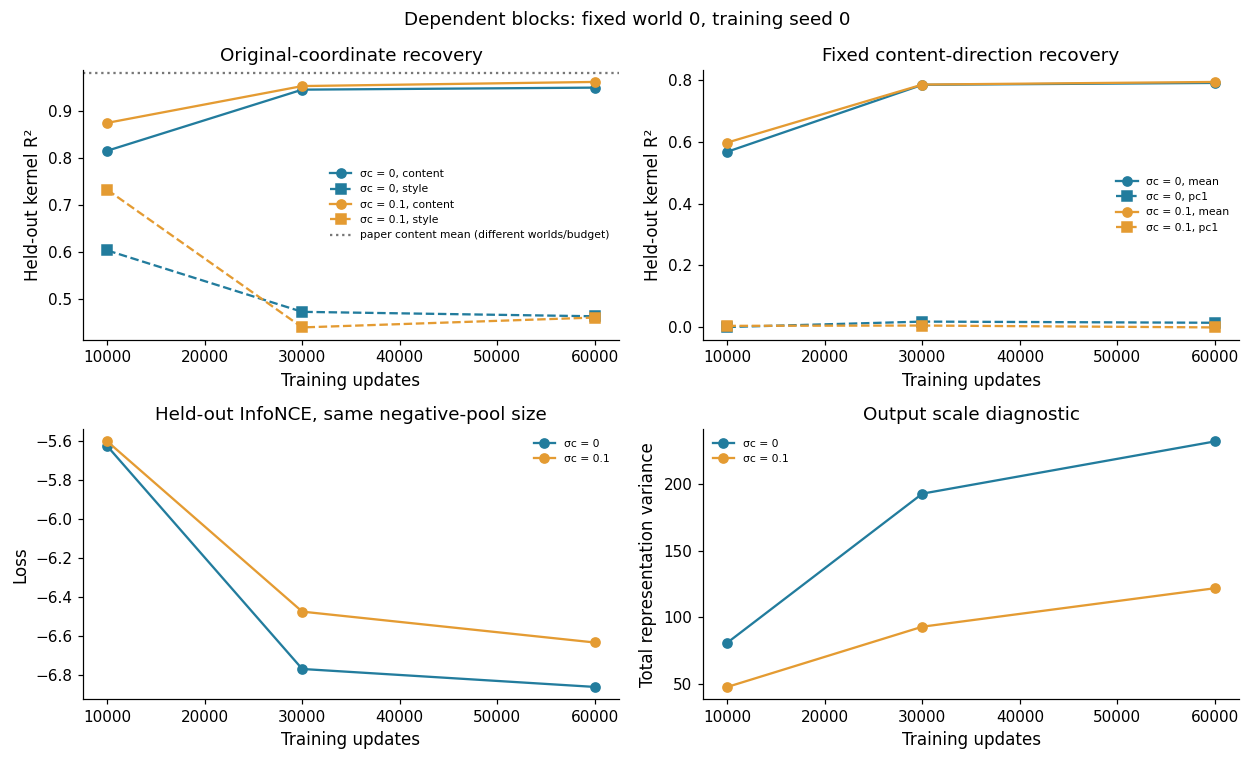

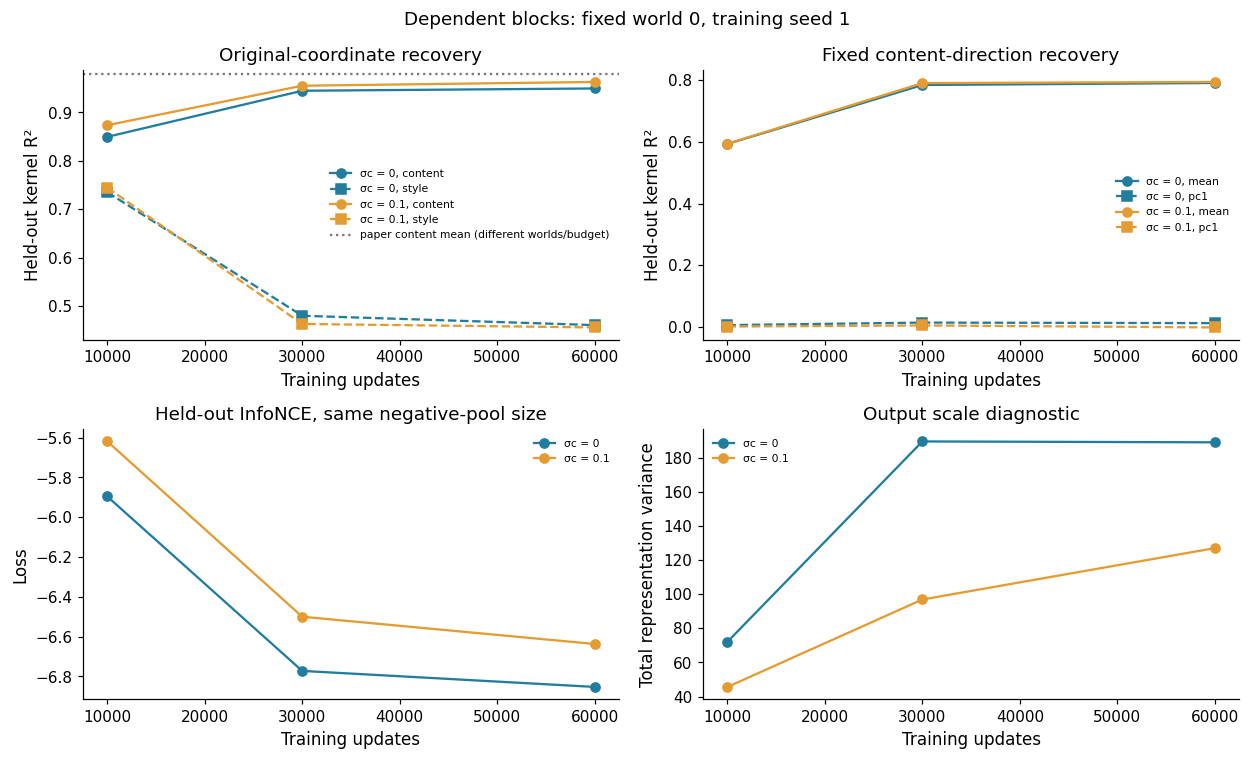

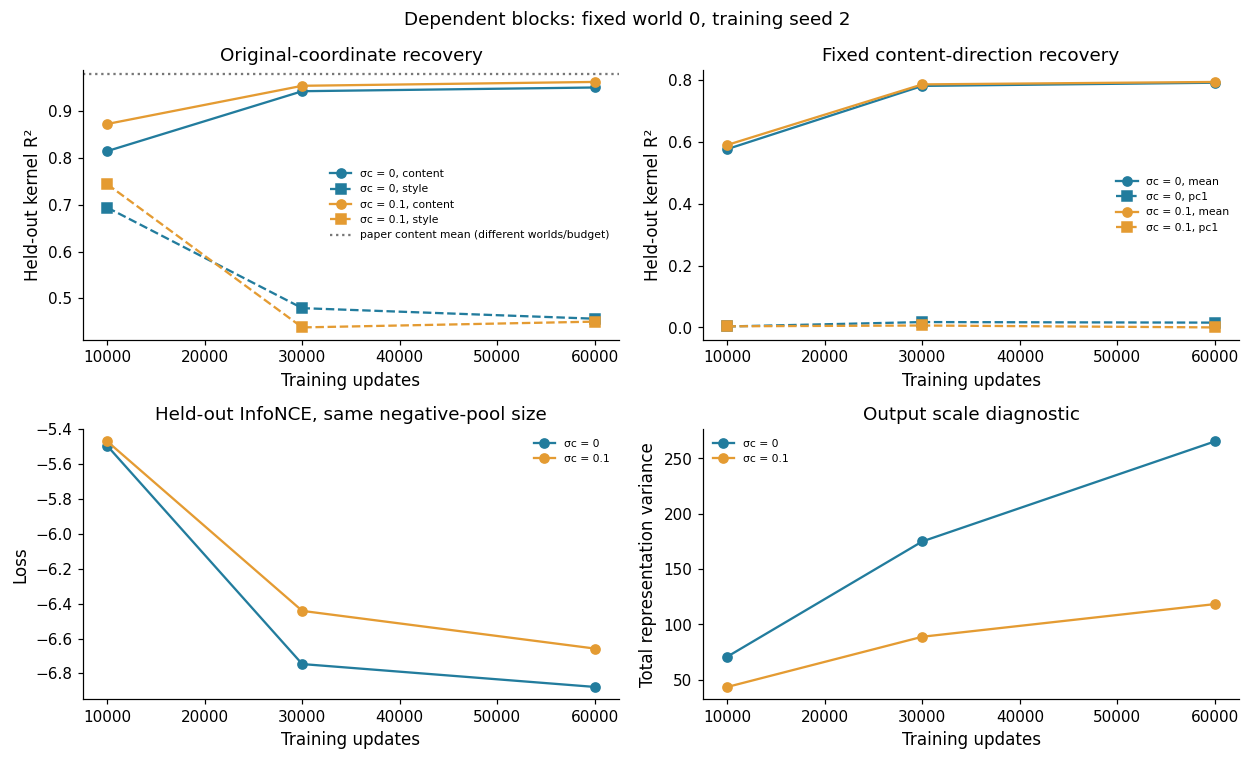

The paper line is contextual, not an expectation of exact numerical agreement at 60k.
Compare loss trajectories over time within each condition; the positive-pair distributions differ between σc conditions.
Output covariance diagnostics measure scale/geometry; they do not count recovered latent dimensions.
Main question: how does longer training affect original-content recovery in the invariant and perturbed runs?
If both content and style scores increase, describe better recoverability rather than cleaner separation.
Model/Adam/RNG checkpoints and encoded arrays are saved in: /content/extension_dependent_blocks_followup


In [16]:
# ADDED [11]: compare the SAME content targets at all budgets and both perturbation strengths.
if RUN_DEPENDENT_FOCUS:
    recovery_cols = ['content_linear', 'content_kernel', 'style_kernel', 'fixed_content_linear',
                     'fixed_content_kernel', 'weakest_content_linear', 'weakest_content_kernel', 'heldout_loss',
                     'output_total_variance', 'output_effective_rank']
    print('Focused results: one row per world, training seed, perturbation strength and budget.')
    display(focus.set_index(['world_seed', 'training_seed', 'sigma_c', 'updates'])[recovery_cols].round(4))
    print('Oracle probe reference uses all WHITENED true content as input. It is not a universal upper bound for learned representations.')
    display(focus_oracle[['world_seed', 'content_linear', 'content_kernel',
                          'fixed_content_linear', 'fixed_content_kernel', 'weakest_content_kernel']].round(4))

    fixed_cols = [f'fixed_kernel_pc{i+1}' for i in range(NC)]
    fixed_per_direction = focus[['world_seed', 'training_seed', 'sigma_c', 'updates'] + fixed_cols]
    fixed_per_direction.to_csv(FOCUS_DIR / 'fixed_content_direction_recovery.csv', index=False)
    print('Direct kernel probes for fixed unit-variance content directions; pc1 has least original population variance.')
    display(fixed_per_direction.set_index(['world_seed', 'training_seed', 'sigma_c', 'updates']).round(4))

    index = ['world_seed', 'training_seed', 'updates']
    invariant = focus[focus.sigma_c == 0.0].set_index(index).sort_index()
    perturbed = focus[focus.sigma_c == CONTENT_SIGMA].set_index(index).sort_index()
    assert invariant.index.equals(perturbed.index)
    paired_difference = perturbed[recovery_cols] - invariant[recovery_cols]
    paired_difference.to_csv(FOCUS_DIR / 'budget_paired_differences.csv')
    print('Paired differences: perturbed minus invariant at the same budget.')
    display(paired_difference.round(4))

    for world_seed in FOCUS_WORLD_SEEDS:
        for training_seed in FOCUS_TRAIN_SEEDS:
            subset = focus[(focus.world_seed == world_seed) & (focus.training_seed == training_seed)]
            fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.0))
            for sigma_c, color in zip(FOCUS_CONTENT_SIGMAS, ['#227c9d', '#e49b32']):
                rows = subset[subset.sigma_c == sigma_c].sort_values('updates')
                label = f'σc = {sigma_c:g}'
                axes[0,0].plot(rows.updates, rows.content_kernel, marker='o', color=color, label=label + ', content')
                axes[0,0].plot(rows.updates, rows.style_kernel, marker='s', linestyle='--', color=color, label=label + ', style')
                axes[0,1].plot(rows.updates, rows.fixed_content_kernel, marker='o', color=color, label=label + ', mean')
                axes[0,1].plot(rows.updates, rows.weakest_content_kernel, marker='s', linestyle='--', color=color, label=label + ', pc1')
                axes[1,0].plot(rows.updates, rows.heldout_loss, marker='o', color=color, label=label)
                axes[1,1].plot(rows.updates, rows.output_total_variance, marker='o', color=color, label=label)
            axes[0,0].axhline(PAPER['dependent_blocks'][0], color='#777777', linestyle=':',
                              label='paper content mean (different worlds/budget)')
            axes[0,0].set(title='Original-coordinate recovery', ylabel='Held-out kernel R²')
            axes[0,1].set(title='Fixed content-direction recovery', ylabel='Held-out kernel R²')
            axes[1,0].set(title='Held-out InfoNCE, same negative-pool size', ylabel='Loss')
            axes[1,1].set(title='Output scale diagnostic', ylabel='Total representation variance')
            for ax in axes.flat:
                ax.set_xlabel('Training updates')
                ax.legend(frameon=False, fontsize=7)
            fig.suptitle(f'Dependent blocks: fixed world {world_seed}, training seed {training_seed}')
            fig.tight_layout()
            fig.savefig(FOCUS_DIR / f'budget_followup_world{world_seed}_train{training_seed}.png', dpi=150)
            plt.show()
    print('The paper line is contextual, not an expectation of exact numerical agreement at 60k.')
    print('Compare loss trajectories over time within each condition; the positive-pair distributions differ between σc conditions.')
    print('Output covariance diagnostics measure scale/geometry; they do not count recovered latent dimensions.')
    print('Main question: how does longer training affect original-content recovery in the invariant and perturbed runs?')
    print('If both content and style scores increase, describe better recoverability rather than cleaner separation.')
    print('Model/Adam/RNG checkpoints and encoded arrays are saved in:', FOCUS_DIR.resolve())

## Historical reference results

The following static tables record the earlier perturbed-only comparison and independent single-seed sweep. They are retained for provenance and are not recomputed by Run All. They are separate from both the main notebook's paired four-setting table and this notebook's fixed-world training-budget study. The historical labels “leaky” and `r_c` denote perturbed original content and its coordinate price, respectively.


### Archived numerical summaries

#### Seed-0 sampled coordinate prices

| Scenario | c1 | c2 | c3 | c4 | c5 | s1 | s2 | s3 | s4 | s5 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| independent_all | 0.01 | 0.01 | 0.01 | 0.01 | 0.01 | 0.997 | 1.004 | 1.016 | 0.997 | 1.009 |
| independent_partial | 0.01 | 0.01 | 0.01 | 0.01 | 0.01 | 0.752 | 0.744 | 0.758 | 0.744 | 0.762 |
| dependent_blocks | 0.01 | 0.01 | 0.01 | 0.01 | 0.01 | 1.813 | 0.944 | 0.838 | 1.279 | 2.233 |
| content_causes_style | 0.01 | 0.01 | 0.01 | 0.01 | 0.01 | 0.228 | 0.176 | 0.317 | 0.422 | 0.842 |

#### Earlier perturbed-only recovery comparison

| Scenario | p(chg.) | Stat. | Cau. | Content c (leaky) | Style s (leaky) | Content c (paper) | Style s (paper) | seeds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| independent_all | 1.00 | ✗ | ✗ | 0.98 ± 0.00 | 0.00 ± 0.00 | 1.00 ± 0.00 | 0.07 ± 0.00 | 3 |
| independent_partial | 0.75 | ✗ | ✗ | 0.98 ± 0.00 | 0.00 ± 0.00 | 1.00 ± 0.00 | 0.06 ± 0.05 | 3 |
| dependent_blocks | 0.75 | ✓ | ✗ | 0.92 ± 0.04 | 0.57 ± 0.30 | 0.98 ± 0.03 | 0.37 ± 0.05 | 3 |
| content_causes_style | 0.75 | ✓ | ✓ | 0.92 ± 0.03 | 0.88 ± 0.06 | 0.99 ± 0.01 | 0.80 ± 0.08 | 3 |

#### Earlier per-coordinate mean recovery

| Scenario | c1 | c2 | c3 | c4 | c5 | s1 | s2 | s3 | s4 | s5 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| independent_all | 0.98 | 0.98 | 0.98 | 0.98 | 0.98 | 0.00 | 0.00 | 0.00 | 0.00 | -0.00 |
| independent_partial | 0.98 | 0.98 | 0.98 | 0.98 | 0.98 | 0.00 | -0.00 | 0.00 | -0.00 | -0.00 |
| dependent_blocks | 0.93 | 0.85 | 0.95 | 0.96 | 0.90 | 0.55 | 0.29 | 0.60 | 0.57 | 0.84 |
| content_causes_style | 0.96 | 0.85 | 0.94 | 0.97 | 0.87 | 0.95 | 0.78 | 0.94 | 0.85 | 0.88 |

#### Earlier independent single-seed sweep

| Row | sigma_c | r_c | content_nonlinear | style_nonlinear |
| --- | --- | --- | --- | --- |
| 0 | 0.0 | 0.00 | 0.970 | 0.007 |
| 1 | 0.1 | 0.01 | 0.980 | -0.000 |
| 2 | 0.3 | 0.09 | 0.984 | 0.000 |
| 3 | 0.6 | 0.36 | 0.954 | 0.007 |
| 4 | 1.0 | 1.00 | 0.440 | 0.462 |

### References

- von Kügelgen et al. (2021). *Self-Supervised Learning with Data Augmentations Provably Isolates Content from Style*. NeurIPS. [Paper](https://arxiv.org/abs/2106.04619). The paper supplies the four Gaussian settings and the contextual recovery values.
- [Released simulation implementation](https://github.com/ysharma1126/ssl_identifiability/tree/ee46a35acf68461172b3eaeeb1d6fbc779fce661), commit `ee46a35acf68461172b3eaeeb1d6fbc779fce661`, particularly `main_mlp.py`, `spaces.py` and `losses.py`. The present content-perturbation experiments extend that simulation design.


## Report Figure 2: recovery across training budgets

The final cell plots original-content and style recovery for the invariant and perturbed conditions at 10,000, 30,000 and 60,000 updates. Each block score averages its five coordinate scores within a run; error bars are sample standard deviations across the three paired training seeds in the fixed Case 3 world.

In the saved results, mean original-content recovery rises from $0.83$ to $0.95$ under invariant content and from $0.87$ to $0.96$ under perturbed content. Mean style recovery is approximately $0.46$ under both conditions at 60,000 updates. These scores describe probe recoverability at the evaluated budgets.

The plotting cell performs no training or probe fitting. It reads the current `focus` table or `extension_dependent_blocks_followup/budget_followup_runs.csv` and checks that all 18 evaluations are present. It exports `exp2_case3_recovery.png`, `exp2_case3_recovery.pdf`, summary tables and a LaTeX figure caption. Regenerating the figure requires the in-memory table or the saved CSV; the embedded figure can be viewed directly.


Case 3: one fixed data-generating setting, three paired training seeds.
Held-out kernel-probe R², mean ± sample SD across seeds; block means formed within each run.


original_content        style  training_seeds
sigma_c updates                                              
0.0     10000        0.83 ± 0.02  0.68 ± 0.07               3
        30000        0.94 ± 0.00  0.48 ± 0.00               3
        60000        0.95 ± 0.00  0.46 ± 0.00               3
0.1     10000        0.87 ± 0.00  0.74 ± 0.01               3
        30000        0.95 ± 0.00  0.45 ± 0.01               3
        60000        0.96 ± 0.00  0.46 ± 0.01               3

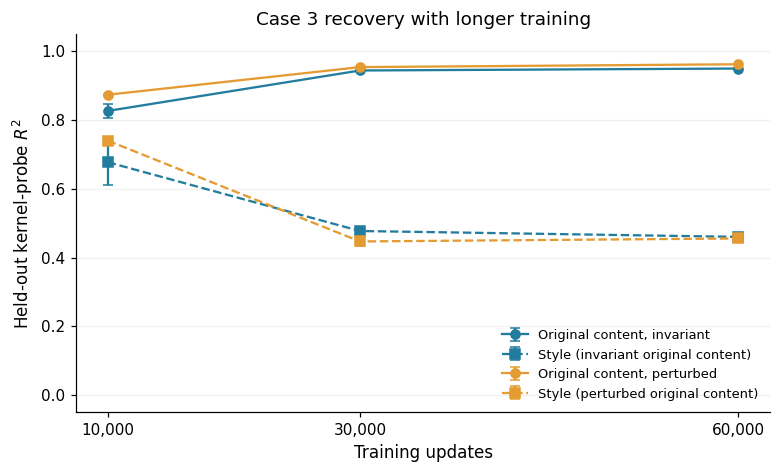

Saved report Figure 2: /content/extension_dependent_blocks_followup/exp2_case3_recovery.png and /content/extension_dependent_blocks_followup/exp2_case3_recovery.pdf
Saved summary tables and LaTeX figure caption in: /content/extension_dependent_blocks_followup
\begin{figure}[htbp]
\centering
\includegraphics[width=0.78\textwidth]{exp2_case3_recovery.pdf}
\caption{Case~3 recovery with longer training in one fixed data-generating setting, using five encoder outputs. Curves show mean held-out kernel-probe $R^2$ for the five original-content factors and the five style factors under invariant and perturbed original content ($\sigma_c=0.1$). Error bars show sample standard deviations across three paired training seeds; block means are formed within each run.}
\label{fig:exp2-case3}
\end{figure}



In [17]:
# ADDED [12]: Figure 2 only. No training or probe fitting in this cell.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPORT_DIR = Path(globals().get('FOCUS_DIR', 'extension_dependent_blocks_followup'))
REPORT_RESULTS_CSV = REPORT_DIR / 'budget_followup_runs.csv'
report_worlds = list(globals().get('FOCUS_WORLD_SEEDS', [0]))
report_seeds = list(globals().get('FOCUS_TRAIN_SEEDS', [0, 1, 2]))
report_sigmas = [0.0, float(globals().get('CONTENT_SIGMA', 0.1))]
report_budgets = list(globals().get('FOCUS_BUDGETS', [10000, 30000, 60000]))
if len(report_worlds) != 1 or len(report_seeds) != 3 or len(set(report_seeds)) != 3:
    raise ValueError('Figure 2 is defined for one fixed Case 3 setting and three distinct training seeds.')

if isinstance(globals().get('focus'), pd.DataFrame) and not focus.empty:
    report_runs = focus.copy()
elif REPORT_RESULTS_CSV.is_file():
    report_runs = pd.read_csv(REPORT_RESULTS_CSV)
else:
    raise FileNotFoundError(
        'Complete the focused training cell, or restore budget_followup_runs.csv '
        'to REPORT_RESULTS_CSV. This plotting cell never starts training.'
    )

report_keys = ['world_seed', 'training_seed', 'sigma_c', 'updates']
report_metrics = ['content_kernel', 'style_kernel']
missing_columns = set(report_keys + report_metrics) - set(report_runs.columns)
if missing_columns:
    raise ValueError(f'Missing result columns: {sorted(missing_columns)}')
report_runs = report_runs[
    report_runs.world_seed.isin(report_worlds)
    & report_runs.training_seed.isin(report_seeds)
    & report_runs.sigma_c.isin(report_sigmas)
    & report_runs.updates.isin(report_budgets)
].copy()
if report_runs.duplicated(report_keys).any():
    raise ValueError('Duplicate evaluations found for the same seed, perturbation strength and budget.')
expected = pd.MultiIndex.from_product(
    [report_worlds, report_seeds, report_sigmas, report_budgets], names=report_keys)
observed = pd.MultiIndex.from_frame(report_runs[report_keys])
missing_runs = expected.difference(observed)
if len(missing_runs):
    raise ValueError(
        f'Figure 2 is not exported because {len(missing_runs)} planned evaluations are missing. '
        f'Missing (world, training seed, sigma_c, updates): {missing_runs.tolist()}. '
        'Complete or restore these runs before reporting three-seed means and SDs.'
    )
if not np.isfinite(report_runs[report_metrics].to_numpy(dtype=float)).all():
    raise ValueError('Figure 2 requires finite recovery scores for every plotted run.')

# The two columns already average the five latent coordinates WITHIN each run.
# This aggregation calculates mean and sample SD (ddof=1) ACROSS training seeds.
report_summary = report_runs.groupby(['sigma_c', 'updates'])[report_metrics].agg(['mean', 'std', 'count'])
if not (report_summary.xs('count', axis=1, level=1) == 3).all().all():
    raise ValueError('Every plotted point must contain exactly three completed training seeds.')

report_table = pd.DataFrame(index=report_summary.index)
for metric, label in [('content_kernel', 'original_content'), ('style_kernel', 'style')]:
    report_table[label] = [f'{mean:.2f} ± {sd:.2f}' for mean, sd in
                           zip(report_summary[(metric, 'mean')], report_summary[(metric, 'std')])]
report_table['training_seeds'] = 3
REPORT_DIR.mkdir(parents=True, exist_ok=True)
report_summary.to_csv(REPORT_DIR / 'exp2_case3_recovery_mean_sd_count.csv')
report_table.to_csv(REPORT_DIR / 'exp2_case3_recovery_table.csv')
print('Case 3: one fixed data-generating setting, three paired training seeds.')
print('Held-out kernel-probe R², mean ± sample SD across seeds; block means formed within each run.')
try:
    display(report_table)
except NameError:
    print(report_table.to_string())

fig, ax = plt.subplots(figsize=(7.2, 4.4))
for sigma_c, color, condition in [(report_sigmas[0], '#227c9d', 'invariant'),
                                 (report_sigmas[1], '#e49b32', 'perturbed')]:
    rows = report_summary.xs(sigma_c, level='sigma_c').reindex(report_budgets)
    ax.errorbar(report_budgets, rows[('content_kernel', 'mean')],
                yerr=rows[('content_kernel', 'std')], color=color, marker='o',
                linestyle='-', capsize=3, label=f'Original content, {condition}')
    ax.errorbar(report_budgets, rows[('style_kernel', 'mean')],
                yerr=rows[('style_kernel', 'std')], color=color, marker='s',
                linestyle='--', capsize=3, label=f'Style ({condition} original content)')
ax.set(title='Case 3 recovery with longer training', xlabel='Training updates',
       ylabel=r'Held-out kernel-probe $R^2$', ylim=(-0.05, 1.05))
ax.set_xticks(report_budgets, [f'{budget:,}' for budget in report_budgets])
ax.legend(frameon=False, fontsize=8.5, loc='lower right')
ax.grid(axis='y', alpha=0.18)
fig.tight_layout()
figure_png = REPORT_DIR / 'exp2_case3_recovery.png'
figure_pdf = REPORT_DIR / 'exp2_case3_recovery.pdf'
fig.savefig(figure_png, dpi=300, bbox_inches='tight')
fig.savefig(figure_pdf, bbox_inches='tight')
plt.show()

# Caption and label match the figure referenced in the report.
report_caption = (
    r'Case~3 recovery with longer training in one fixed data-generating setting, '
    r'using five encoder outputs. Curves show mean held-out kernel-probe $R^2$ '
    r'for the five original-content factors and the five style factors under '
    r'invariant and perturbed original content '
    rf'($\sigma_c={report_sigmas[1]:g}$). '
    r'Error bars show sample standard deviations across three paired training seeds; '
    r'block means are formed within each run.'
)
latex_figure = (
    '\\begin{figure}[htbp]\n\\centering\n'
    '\\includegraphics[width=0.78\\textwidth]{exp2_case3_recovery.pdf}\n'
    '\\caption{' + report_caption + '}\n'
    '\\label{fig:exp2-case3}\n\\end{figure}\n'
)
(REPORT_DIR / 'exp2_case3_recovery_caption.tex').write_text(latex_figure)
print('Saved report Figure 2:', figure_png.resolve(), 'and', figure_pdf.resolve())
print('Saved summary tables and LaTeX figure caption in:', REPORT_DIR.resolve())
print(latex_figure)
